# Van SQL en Cypher naar RAG en GraphRAG
## Eén fictieve filmcatalogus, verschillende manieren om feiten terug te vinden

**Voor HBO-ICT AI.** Begin bij een bekende databasevraag en eindig bij een onderbouwd modelantwoord.
PostgreSQL en Neo4j zijn de databases; pgAdmin 4 en Neo4j Desktop zijn de bijbehorende queryomgevingen.

Dit notebook is opgeslagen met **echt uitgevoerde outputs**. Zonder installatie kun je alles hieronder bekijken.
Alle filmfeiten en bronfiches S1–S4 zijn **fictieve onderwijsgegevens**.

**Leesroute:** 1 dataset → 2 talen → 3 echte plannen → 4 RAG → 5 zoekoppervlak → 6 vijf retrievers → 7 bewijs → 8 beperkingen.

De voorbereidende schrijfcommando's staan in [HANDLEIDING.md](HANDLEIDING.md). Dit notebook importeert of verwijdert
geen databasegegevens: het leest de voorbereide demo, maakt echte lokale modelcalls en schrijft alleen lokale figuren/resultaten.
Wie alleen kijkt, heeft geen database, Python-omgeving of actief taalmodel nodig.

In [1]:
import json, logging, platform
from pathlib import Path
from IPython.display import display, Image, Markdown
from film_demo import catalogue, settings, graph, check_data, answer_and_plans, check_embeddings, query
from film_demo import QUESTION_A, QUESTION_B, QUESTION_C
from notebook_view import table, pg_rows, neo_rows, explain_plans, route_overview, route_answer
from figures import build_figures
logging.getLogger('neo4j.notifications').setLevel(logging.ERROR)
data, config = catalogue(), settings()  # Nooit config of .env afdrukken.
controle = check_data(config)
table([controle])

personen,films,deelnames,inhoud_gelijk
4,4,7,True


# 1. Vraag en dataset

**Vraag A:** Met wie speelde Noor samen in een film?

Noor is `P27`. Dat is onze **zakelijke identifier**, niet een intern recordnummer of RAM-adres.
Genre is een eigenschap van een film, geen apart knooptype. `samenvatting` en `source_id` staan in beide databases.
De embeddings en indexen in Neo4j zijn later toegevoegde, afgeleide zoekgegevens.

Eén inspecteerbare bron: [data/films.json](data/films.json). SQL-import, Cypher-import en de vier bronfiches worden daarvan afgeleid.

In [2]:
table(data['persons'])
table([{k:v for k,v in m.items() if k != 'samenvatting'} for m in data['movies']])
table(data['acted_in'])

person_id,name
P27,Noor
P28,Amir
P29,Sara
P30,Luca


movie_id,title,genre,source_id
M1,Laatste Ronde,actie,S1
M2,Tweede Naam,thriller,S2
M3,Zomerlicht,drama,S3
M4,Schaduwspel,thriller,S4


person_id,movie_id
P27,M1
P28,M1
P28,M2
P29,M2
P29,M3
P30,M3
P30,M4


### Bronfiches

[S1 — Laatste Ronde](sources/S1.md) · [S2 — Tweede Naam](sources/S2.md) ·
[S3 — Zomerlicht](sources/S3.md) · [S4 — Schaduwspel](sources/S4.md).
Iedere fiche bevat titel, genre, samenvatting, cast en bron-ID. Een bron-ID maakt een verzonnen feit inspecteerbaar;
het maakt dat feit niet tot extern geverifieerde filmkennis.

In [3]:
for movie in data['movies']:
    display(Markdown(f"**{movie['source_id']} · {movie['title']}** — {movie['samenvatting']}"))

**S1 · Laatste Ronde** — Een jonge bokser probeert na een zware nederlaag terug te keren in de ring. Met hulp van een onverwachte trainingspartner bereidt hij zich voor op zijn laatste kans op een titel.

**S2 · Tweede Naam** — Een vrouw bouwt na een vlucht een nieuw leven op onder andermans naam. Wanneer haar verleden opduikt, moet ze kiezen tussen haar aangenomen identiteit en de waarheid.

**S3 · Zomerlicht** — Twee familieleden keren terug naar hun geboortedorp om een geërfd huis op te knappen. Tijdens de zomer ontdekken ze waarom hun familie jarenlang uit elkaar bleef.

**S4 · Schaduwspel** — Een koerier ontdekt dat iemand zijn identiteit gebruikt. Hij neemt zelf een andere naam aan om de dader te vinden en raakt steeds verder verstrikt in een leven dat niet van hem is.

# 2. SQL versus Cypher

De relationele variant gebruikt `person`, `movie` en koppeltabel `acted_in`, met primaire sleutels,
foreign keys en een omgekeerde index op `(movie_id, person_id)`. Neo4j gebruikt `Person`, `Movie` en `ACTED_IN`,
met uniekheidsconstraints op `person_id` en `movie_id`.

De volgende afbeeldingen zijn **reproduceerbare schema's**, geen inspecties van geheugenadressen of live recordtoegang.

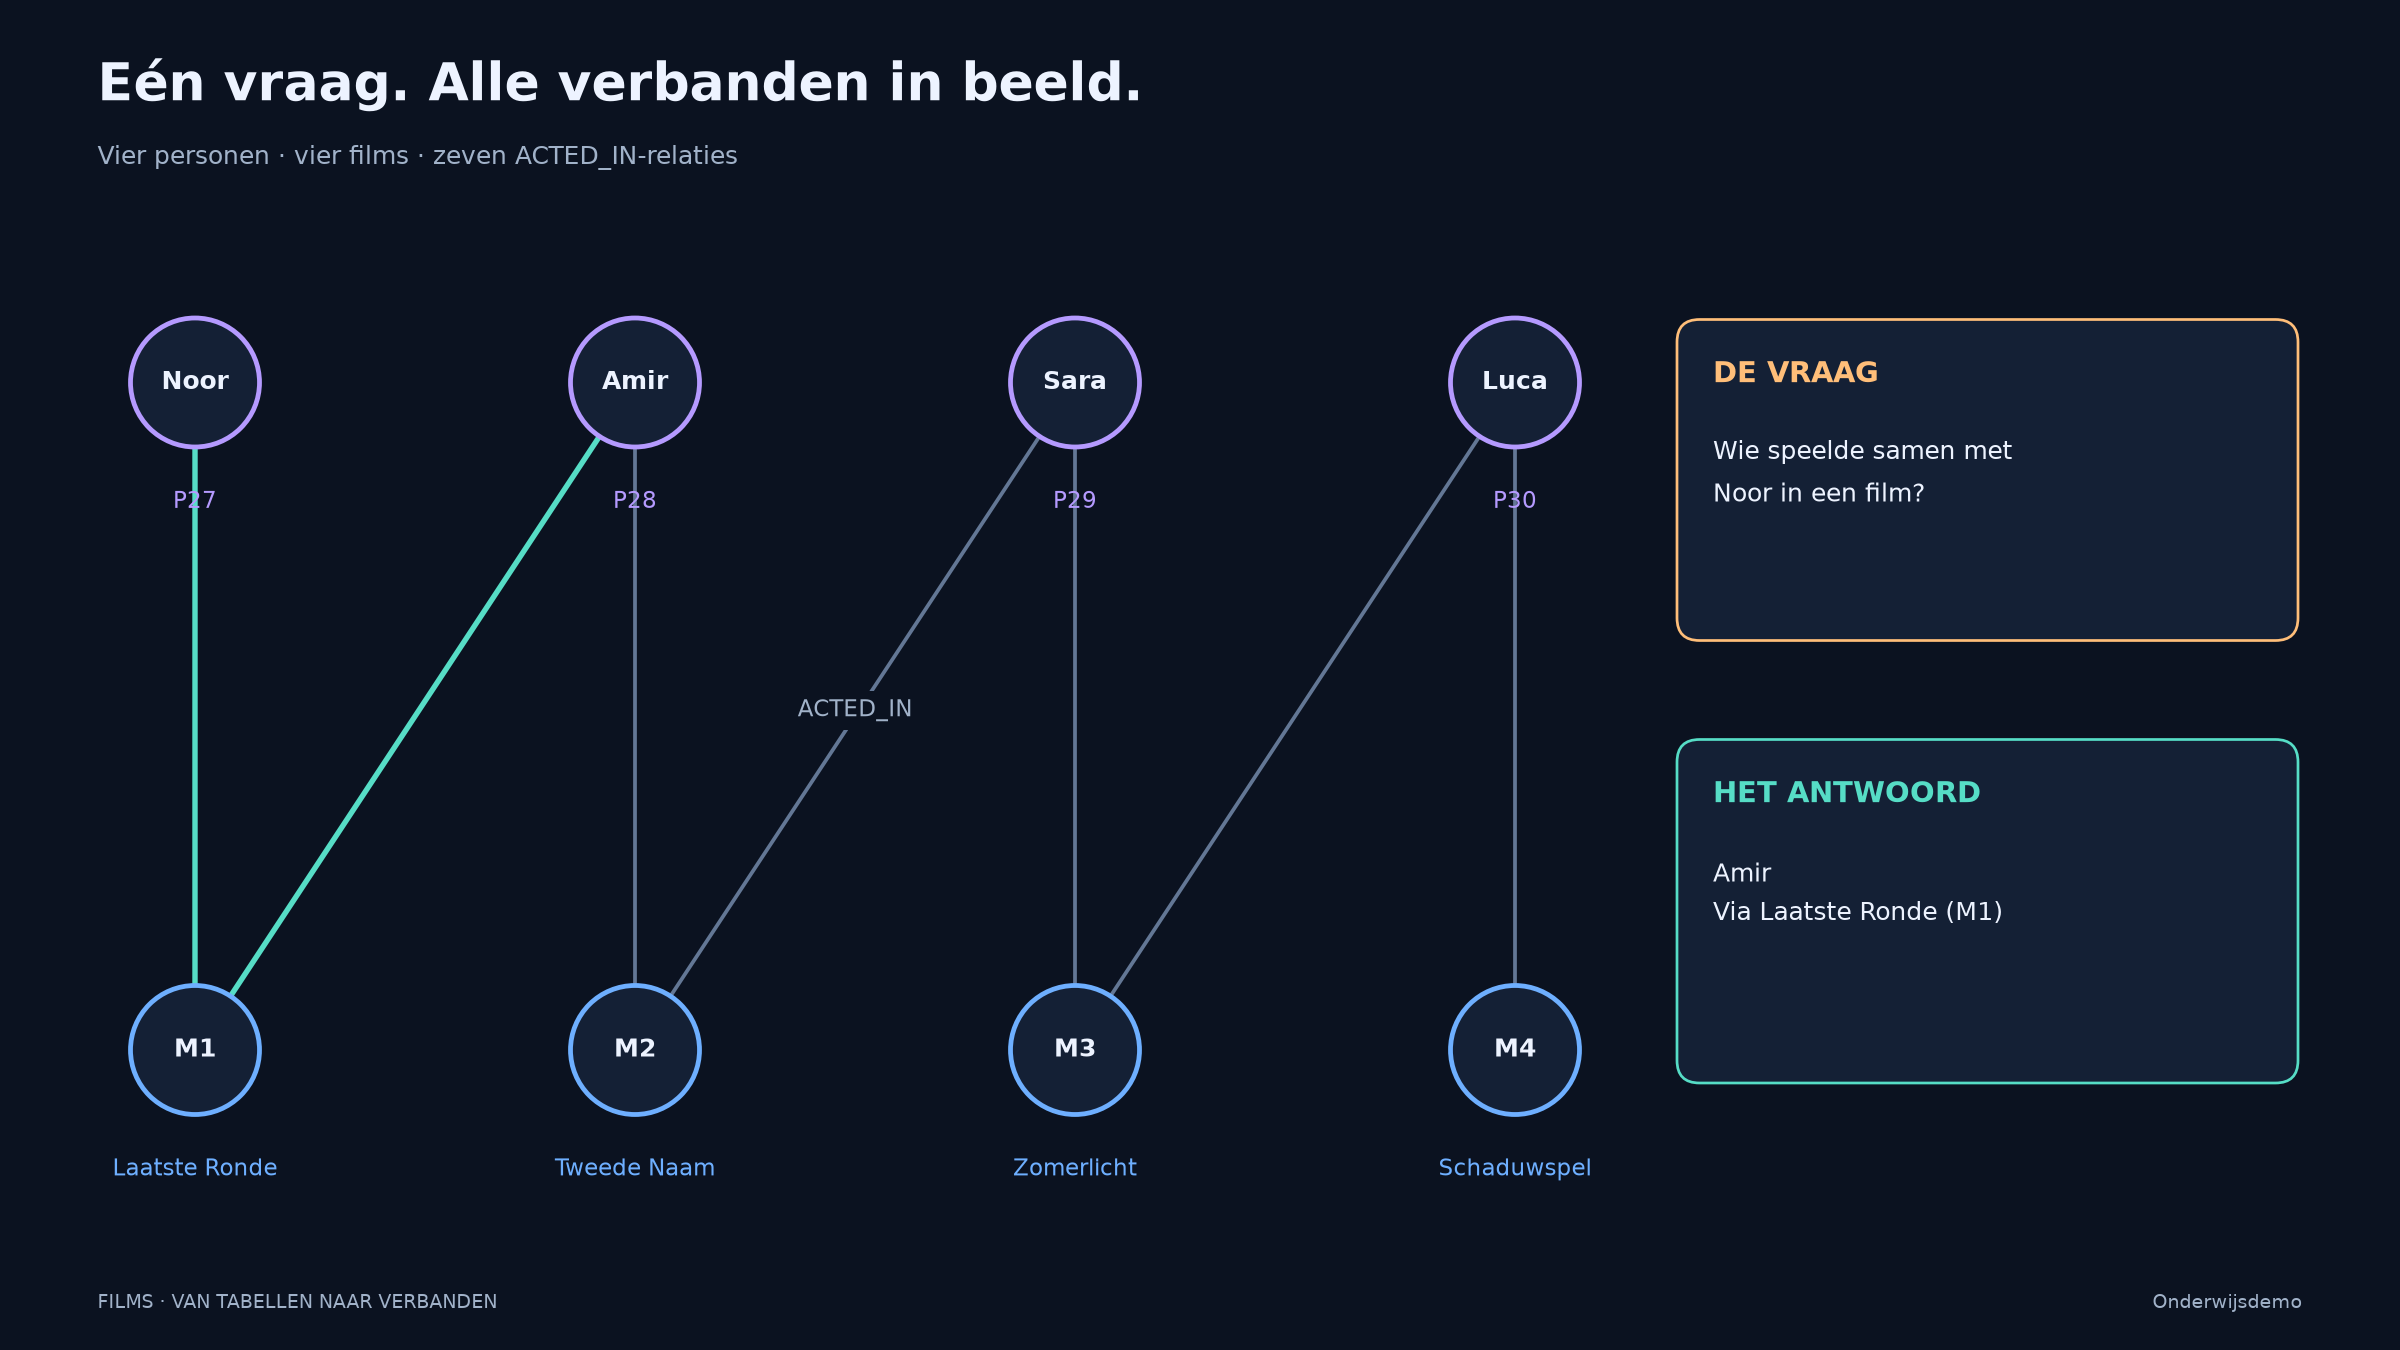

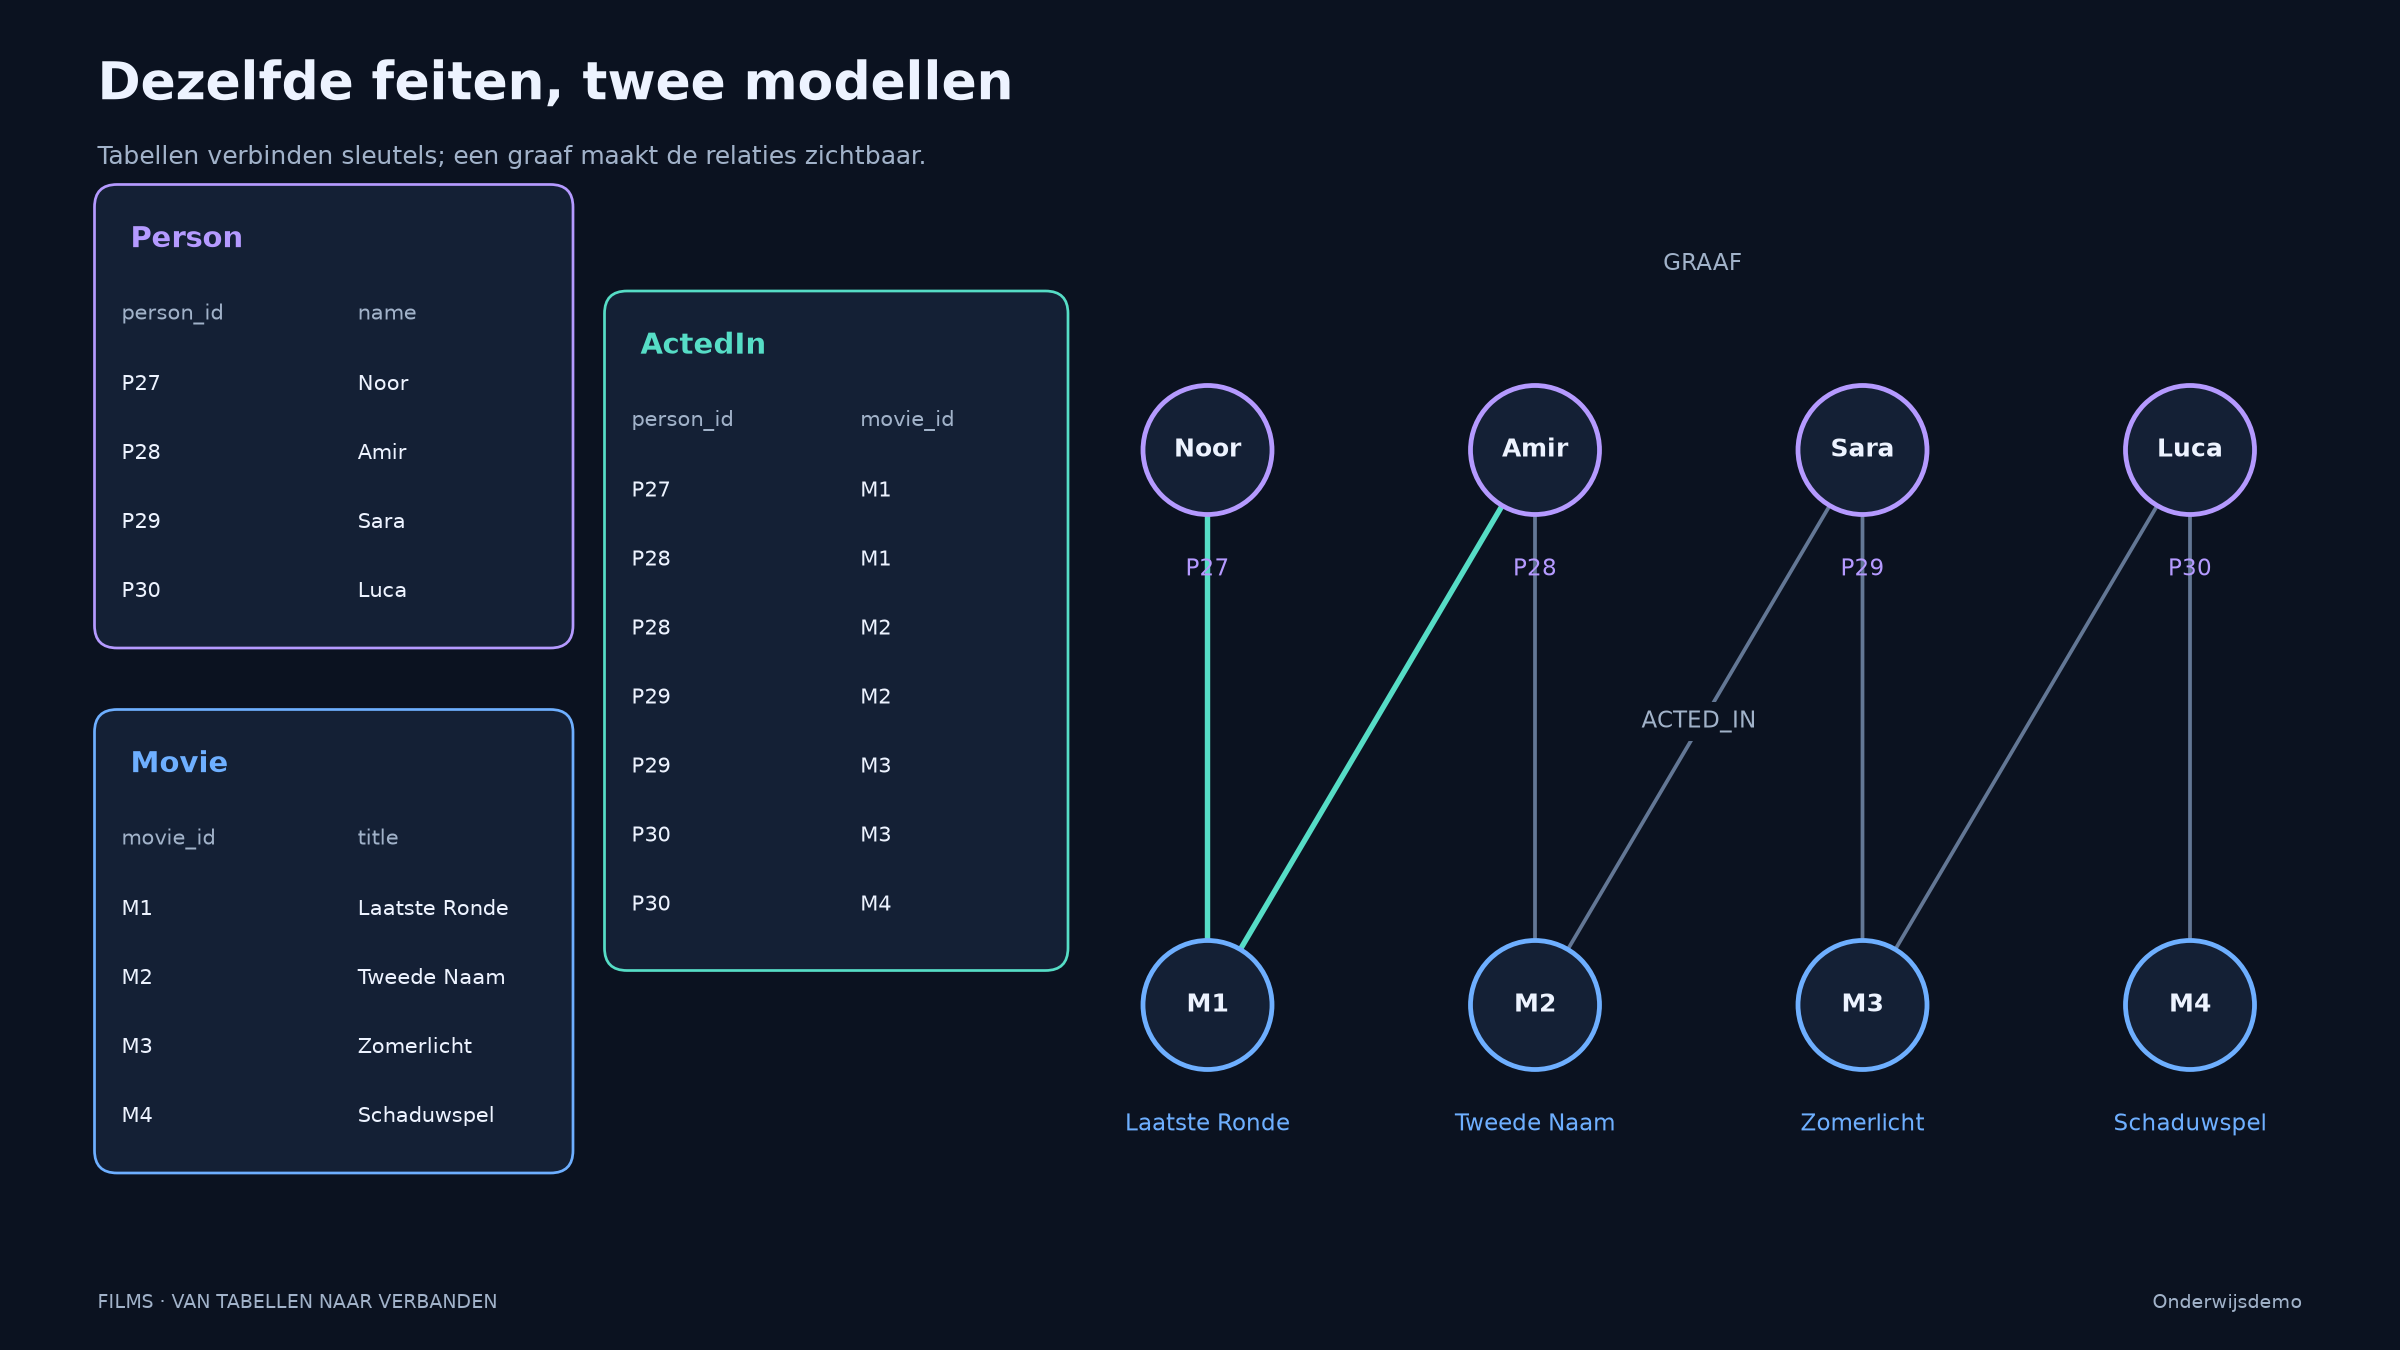

In [4]:
uitslag = answer_and_plans(config)
figuren = build_figures(data, query('collegas.sql'), query('collegas.cypher'),
                        uitslag['postgres_plan'], uitslag['neo4j_plan'])
display(Image(filename='assets/preview.png'))
display(Image(filename='assets/modelvergelijking.png'))

### Eén vraag, twee talen

Beide query's selecteren Noor via `P27`, sluiten Noor zelf uit, verwijderen dubbele collega's en sorteren op naam en zakelijke ID.
Ze leveren dezelfde kolommen: `person_id` en `name`.

**Waarom geen `movie`-join in SQL?** Voor alleen de naam van een collega is de gedeelde `movie_id` in twee deelnames voldoende.
Een extra join zou hier geen benodigde informatie toevoegen. De querybestanden zijn de enige centrale querydefinities.

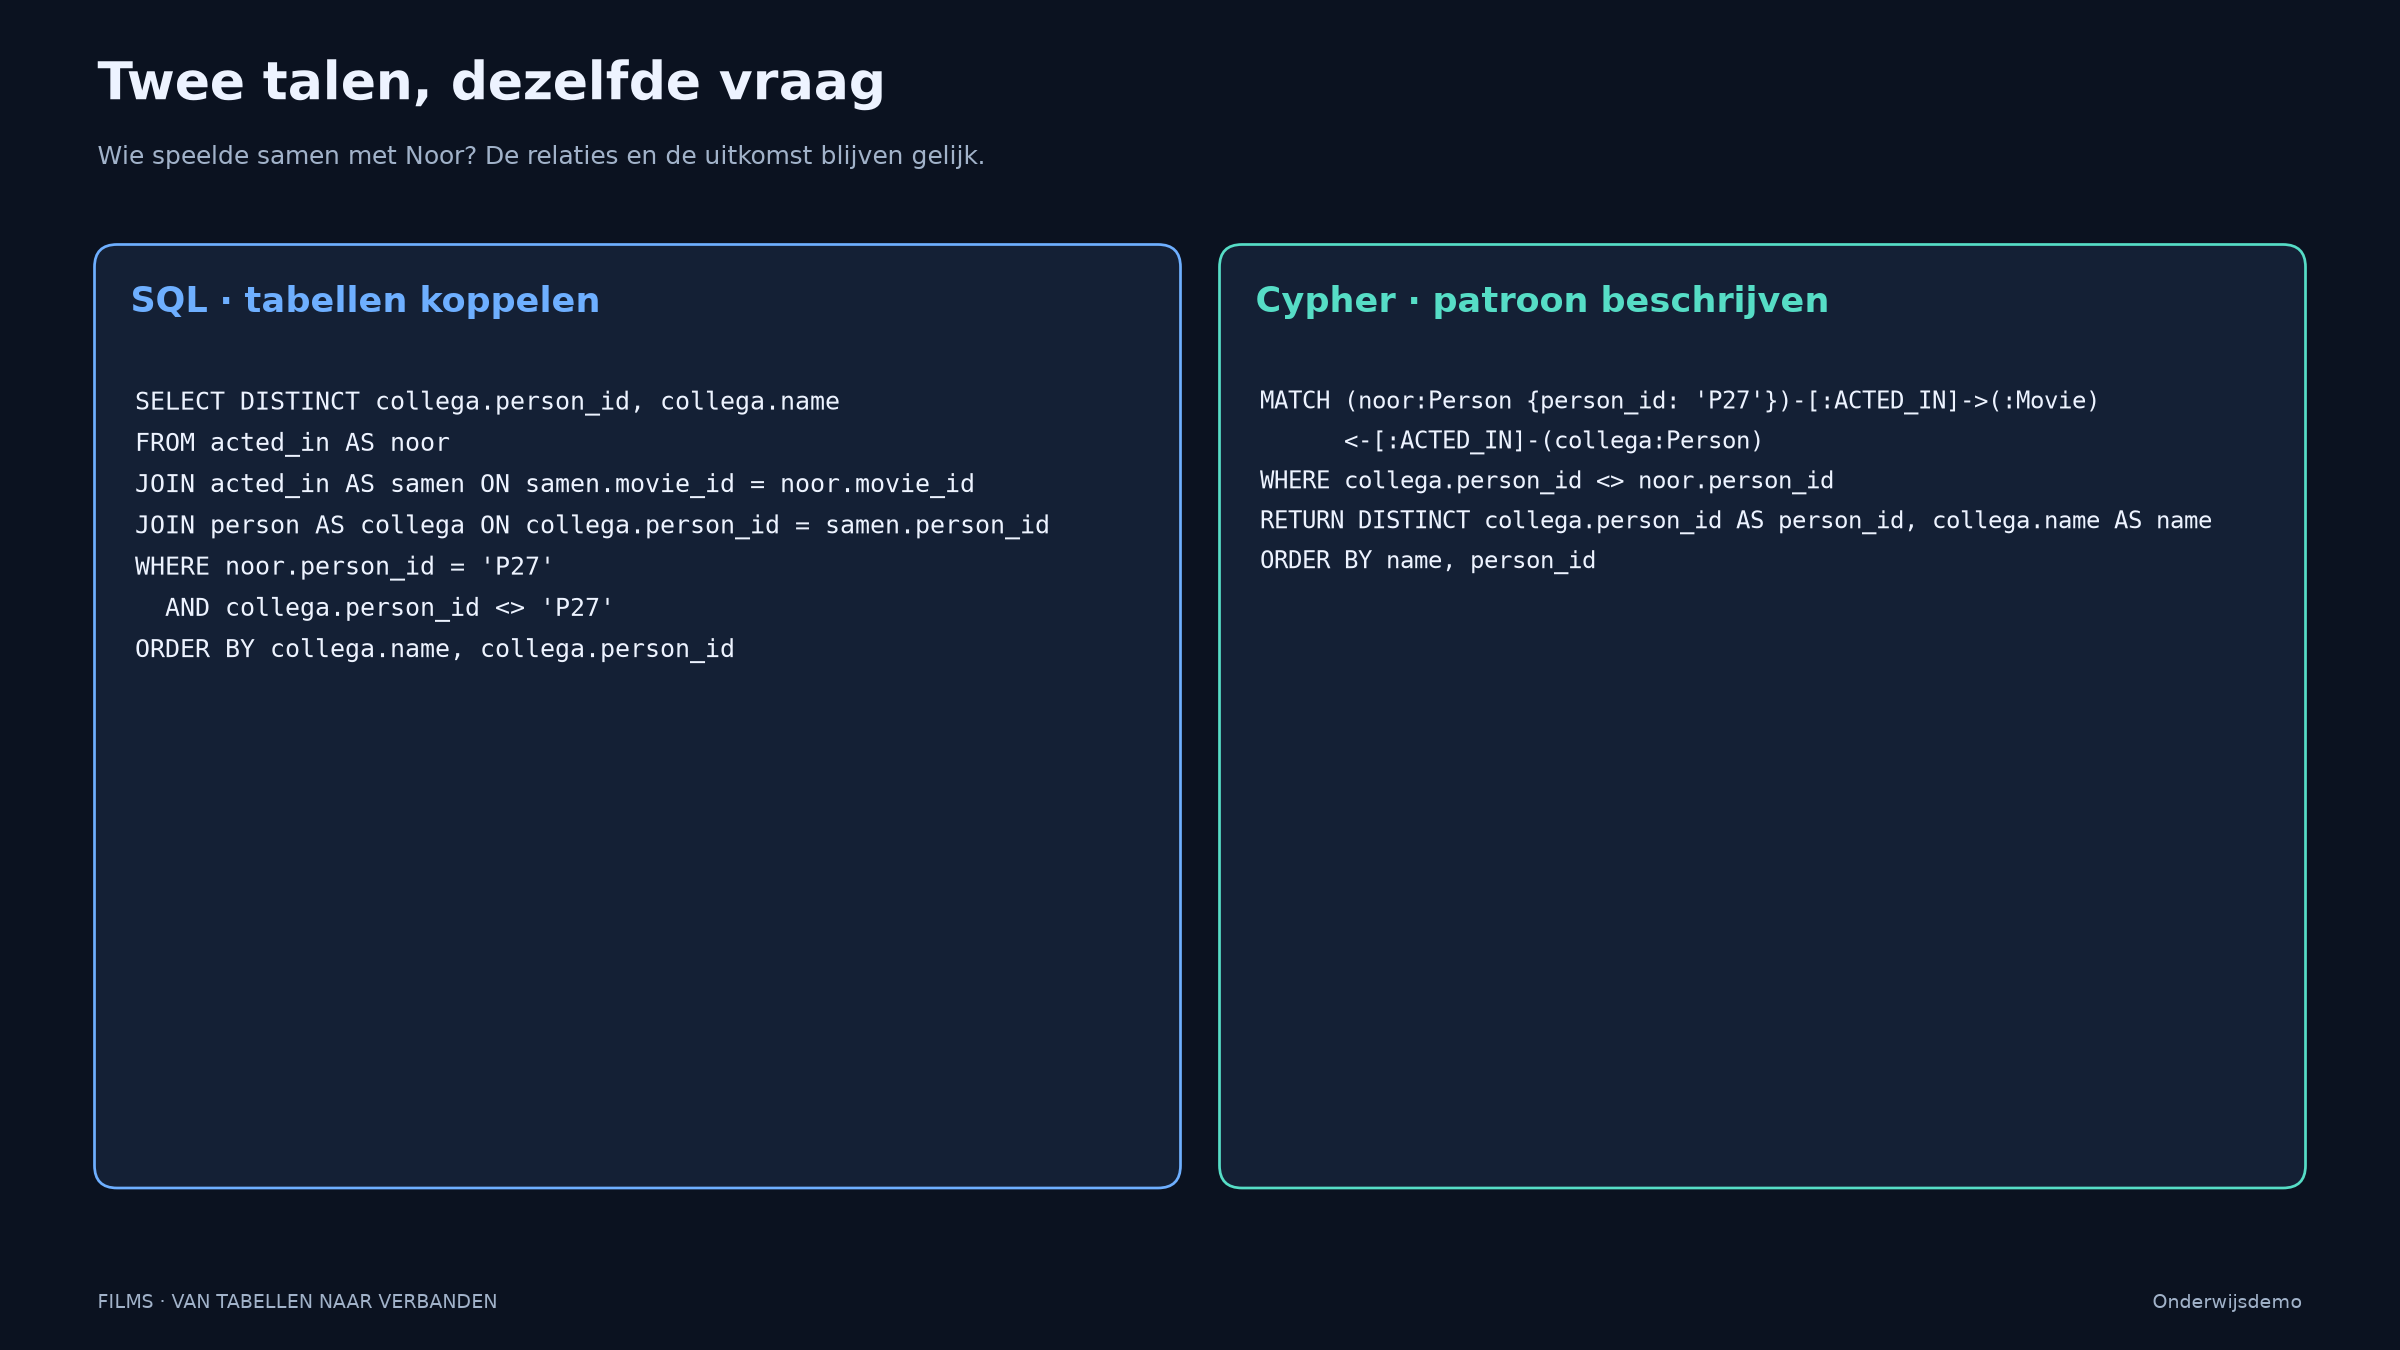

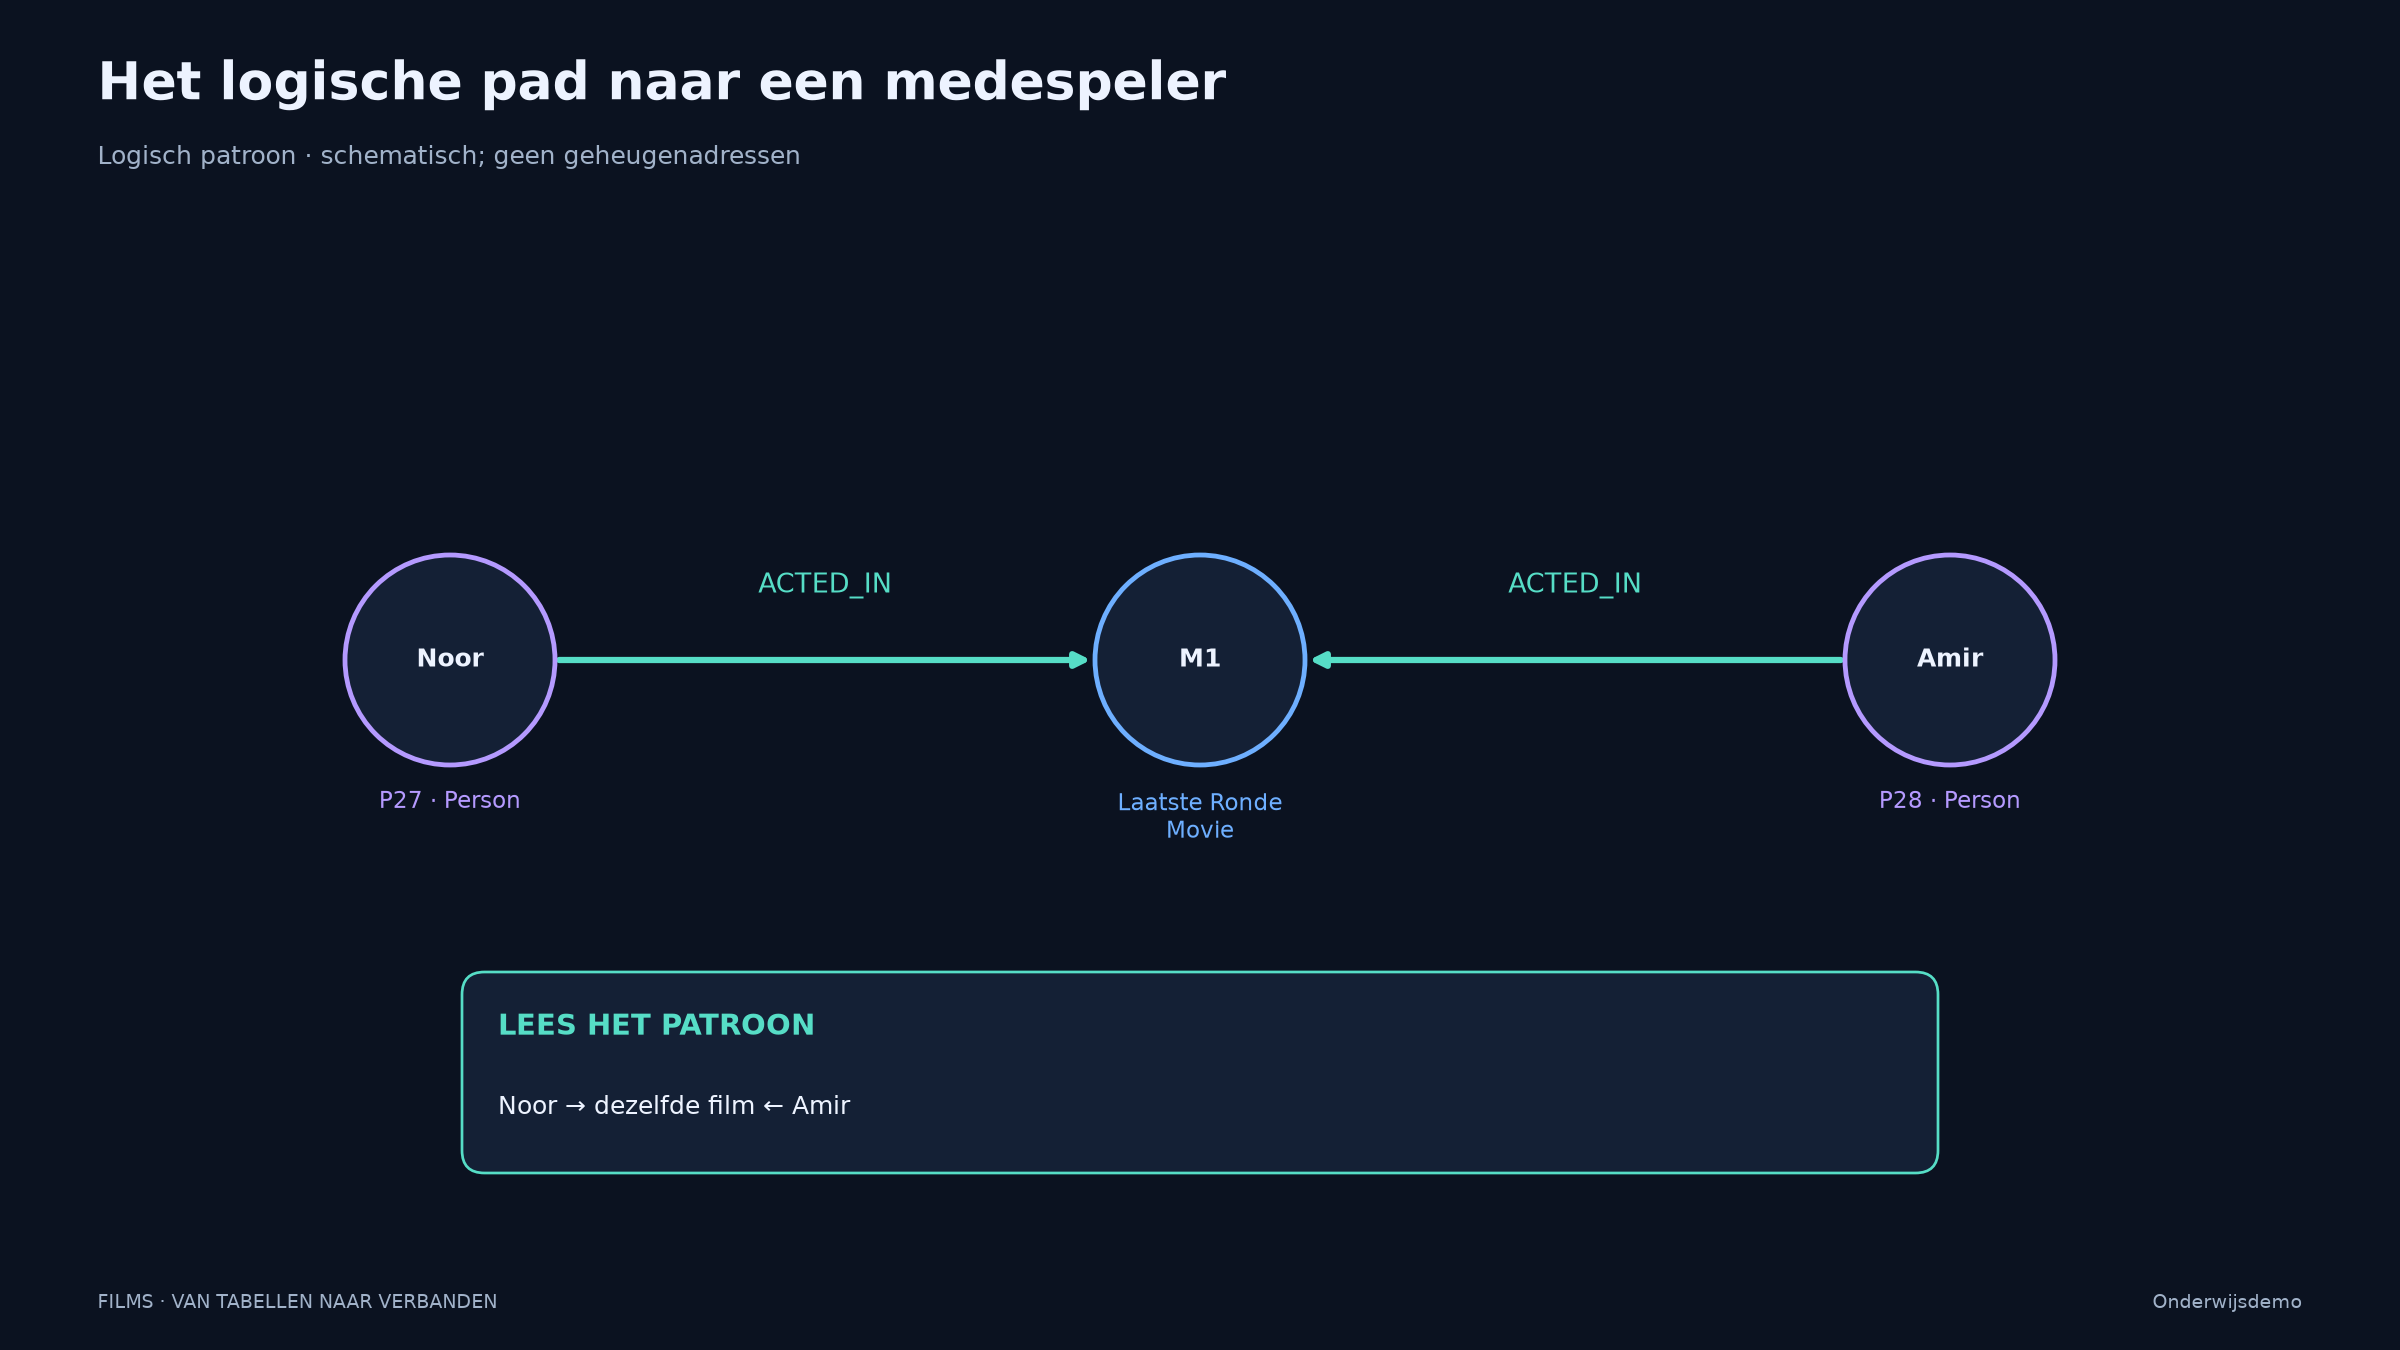

In [5]:
display(Image(filename='assets/twee-talen.png'))
display(Image(filename='assets/logisch-pad.png'))

# 3. Resultaten en werkelijk gekozen uitvoeringsplannen

Het getekende pad **Noor → Laatste Ronde ← Amir** beschrijft het logische patroon.
Het fysieke plan kan daarnaast scans, indexzoekacties, koppelingen, filters, sorteringen en ontdubbelen bevatten.
Dat plan wordt door de database gekozen; een mooie pijlendiagram bewijst niet welke recordtoegang plaatsvond.

In [6]:
table(uitslag['sql'])
table(uitslag['cypher'])
assert uitslag['sql'] == uitslag['cypher'] == [{'person_id':'P28', 'name':'Amir'}]
print('Gecontroleerd: beide antwoordsets zijn gelijk en bevatten exact Amir.')

person_id,name
P28,Amir


person_id,name
P28,Amir


Gecontroleerd: beide antwoordsets zijn gelijk en bevatten exact Amir.


### Echte plannen, zonder snelheidswedstrijd

PostgreSQL werd bevraagd met `EXPLAIN (ANALYZE, BUFFERS, FORMAT JSON)` en Neo4j met `PROFILE`.
`ANALYZE`/`PROFILE` voeren de leesquery echt uit. Voor alleen geschatte plannen kun je `EXPLAIN` gebruiken.
Onderstaande operatoren en aantallen zijn afkomstig uit **deze uitvoering**. De diagramindeling is schematisch,
maar de weergegeven operators zijn niet verzonnen. `DB hits` zijn geen tijdseenheden of PostgreSQL-bufferhits.

De ruwe plannen blijven beschikbaar in [artifacts/uitvoering.json](artifacts/uitvoering.json).
Daarin kan PostgreSQL server-/profileringstijd staan: één geprofileerde uitvoering na de gewone leesquery,
met mogelijk warme caches. We meten geen clienttijd, herhalen hier geen benchmark en berekenen geen snelheidsverhouding.

stap,object,werkelijke_rijen,lussen
Unique,,1.0,1
Sort,,1.0,1
Hash Join,,1.0,1
Hash Join,,2.0,1
Seq Scan,acted_in,7.0,1
Hash,,1.0,1
Seq Scan,acted_in,1.0,1
Hash,,3.0,1
Seq Scan,person,3.0,1


stap,werkelijke_rijen,DB_hits,details
ProduceResults,1,0,"person_id, name"
Sort,1,0,"name ASC, person_id ASC"
Distinct,1,2,"cache[collega.person_id] AS person_id, collega.name AS name"
Filter,1,4,NOT anon_2 = anon_0 AND NOT cache[collega.person_id] = cache[noor.person_id] AND collega:Person
Expand(All),2,3,(anon_1)<-[anon_2:ACTED_IN]-(collega)
Filter,1,2,anon_1:Movie
Expand(All),1,1,(noor)-[anon_0:ACTED_IN]->(anon_1)
NodeUniqueIndexSeek,1,2,"UNIQUE noor:Person(person_id) WHERE person_id = $autostring_0, cache[noor.person_id]"


**Dit koos deze uitvoering werkelijk:**

- PostgreSQL: toegang via **Seq Scan**; koppeling via **Hash Join**. De planner kiest deze combinatie voor de huidige tabellen, indexen en statistieken.
- Neo4j: beginpunt via **NodeUniqueIndexSeek**; relatie-uitbreiding via **Expand(All)**. Een index-zoekactie wordt dus alleen genoemd als die echt in dit plan staat.
- Sortering en ontdubbelen horen ook bij de query; een logisch pad is niet het volledige fysieke plan.
- Rijen en DB hits zijn verschillende meeteenheden. PostgreSQL-bufferhits zijn geen Neo4j-DB hits.

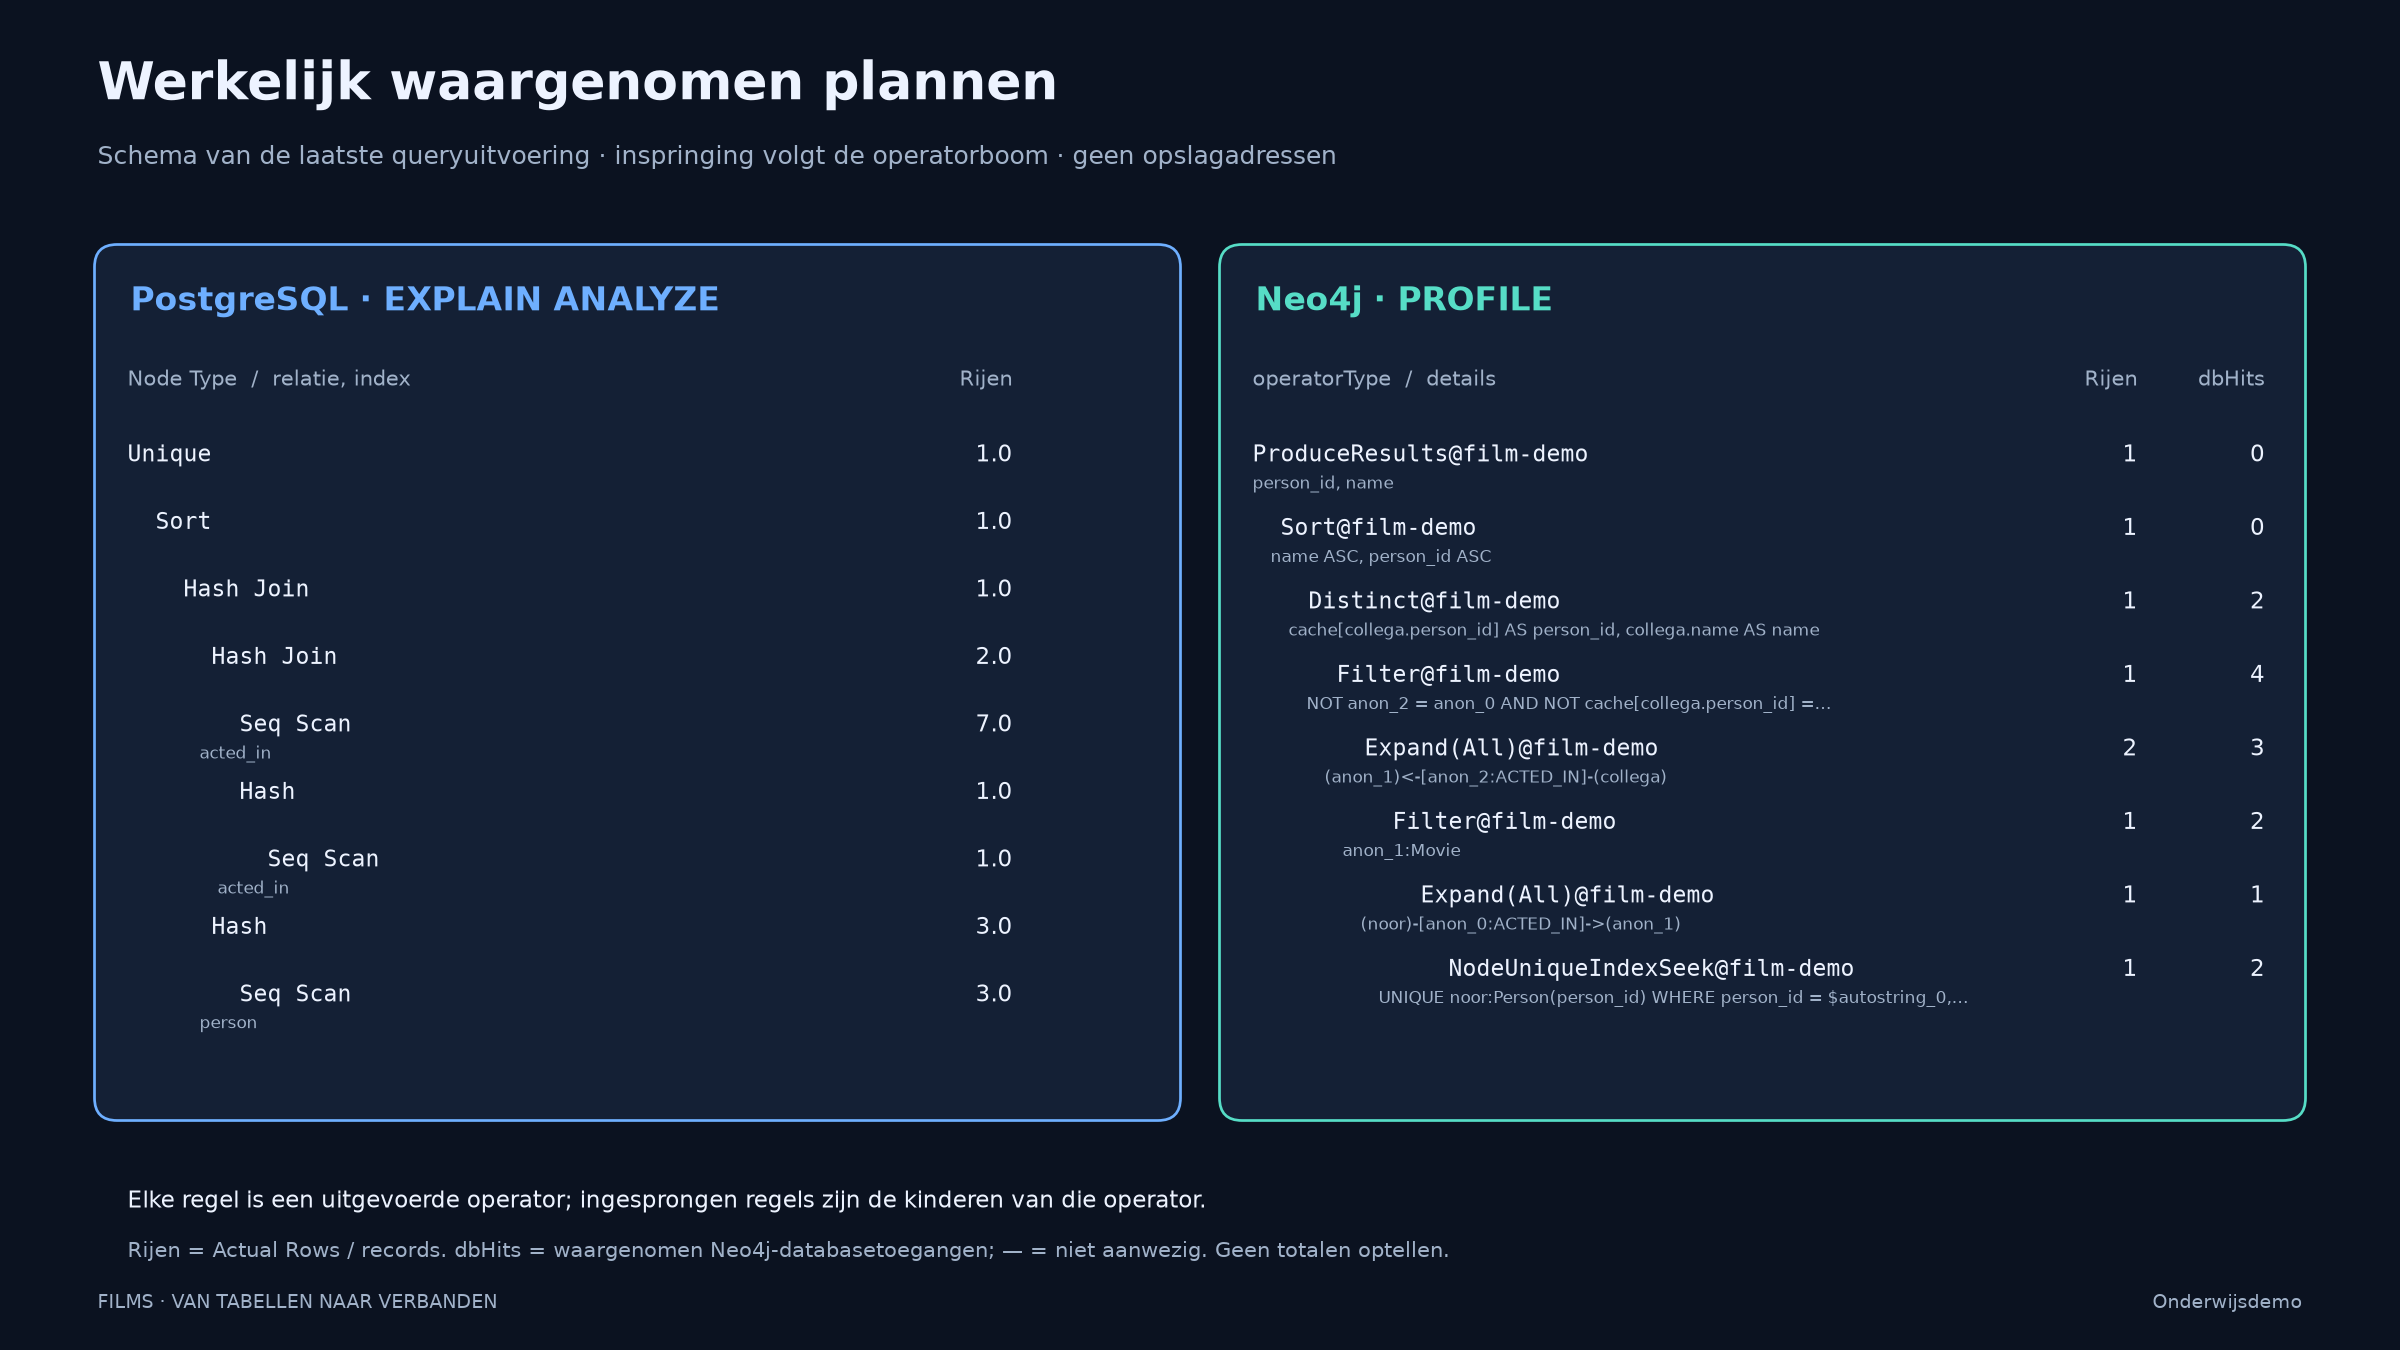

In [7]:
table(pg_rows(uitslag['postgres_plan']['Plan']))
table(neo_rows(uitslag['neo4j_plan']))
explain_plans(uitslag)
display(Image(filename='assets/plannen.png'))

### Wat is dan het interne verschil?

In een property graph zijn relaties expliciete graafelementen met een type en richting. Cypher kan ze direct als een patroon beschrijven.
PostgreSQL legt diezelfde feiten hier vast in rijen met verwijzende sleutels. Beide engines hebben planners, indexen, caches en transacties.
Ook Neo4j kan op deze kleine dataset een scan verkiezen; SQL kan een efficiënte geïndexeerde join kiezen.

Een opgeslagen relatie is **geen gegarandeerde fysieke RAM-pointer**. Het opslagformaat, de versie en editie zijn relevant.
We tonen geen klassiek 15-/34-byte-recordmodel alsof dat de gemeten fysieke opslag van deze instantie is.
[Officiële uitleg over Neo4j-opslagformaten](https://neo4j.com/docs/operations-manual/current/database-internals/store-formats/).

# 4. Van filmzoeken naar RAG

**Retrieval-Augmented Generation:** eerst gegevens ophalen, dan die gegevens als context naast de vraag plaatsen,
en pas daarna een LLM een antwoord laten formuleren. Alleen vectorzoeken is dus nog geen volledige RAG-pipeline.

We onderscheiden drie vragen:

| Vraag | Benodigde informatie |
|---|---|
| A. Met wie speelde Noor samen? | Expliciete castrelaties |
| B. Welke films gaan over iemand die onder een andere identiteit leeft? Leg uit waarom. | Betekenis van samenvattingen |
| C. Welke film heeft dat thema én een acteur die met Noor samenspeelde? | Tekstbetekenis én een specifieke relatievoorwaarde |

**Tweede Naam en Schaduwspel passen inhoudelijk bij B.** Een thrillerfilter houdt ze allebei over.
Voor C is de verbinding via Amir en Laatste Ronde doorslaggevend. Het model moet dat relatiebewijs daadwerkelijk ontvangen.

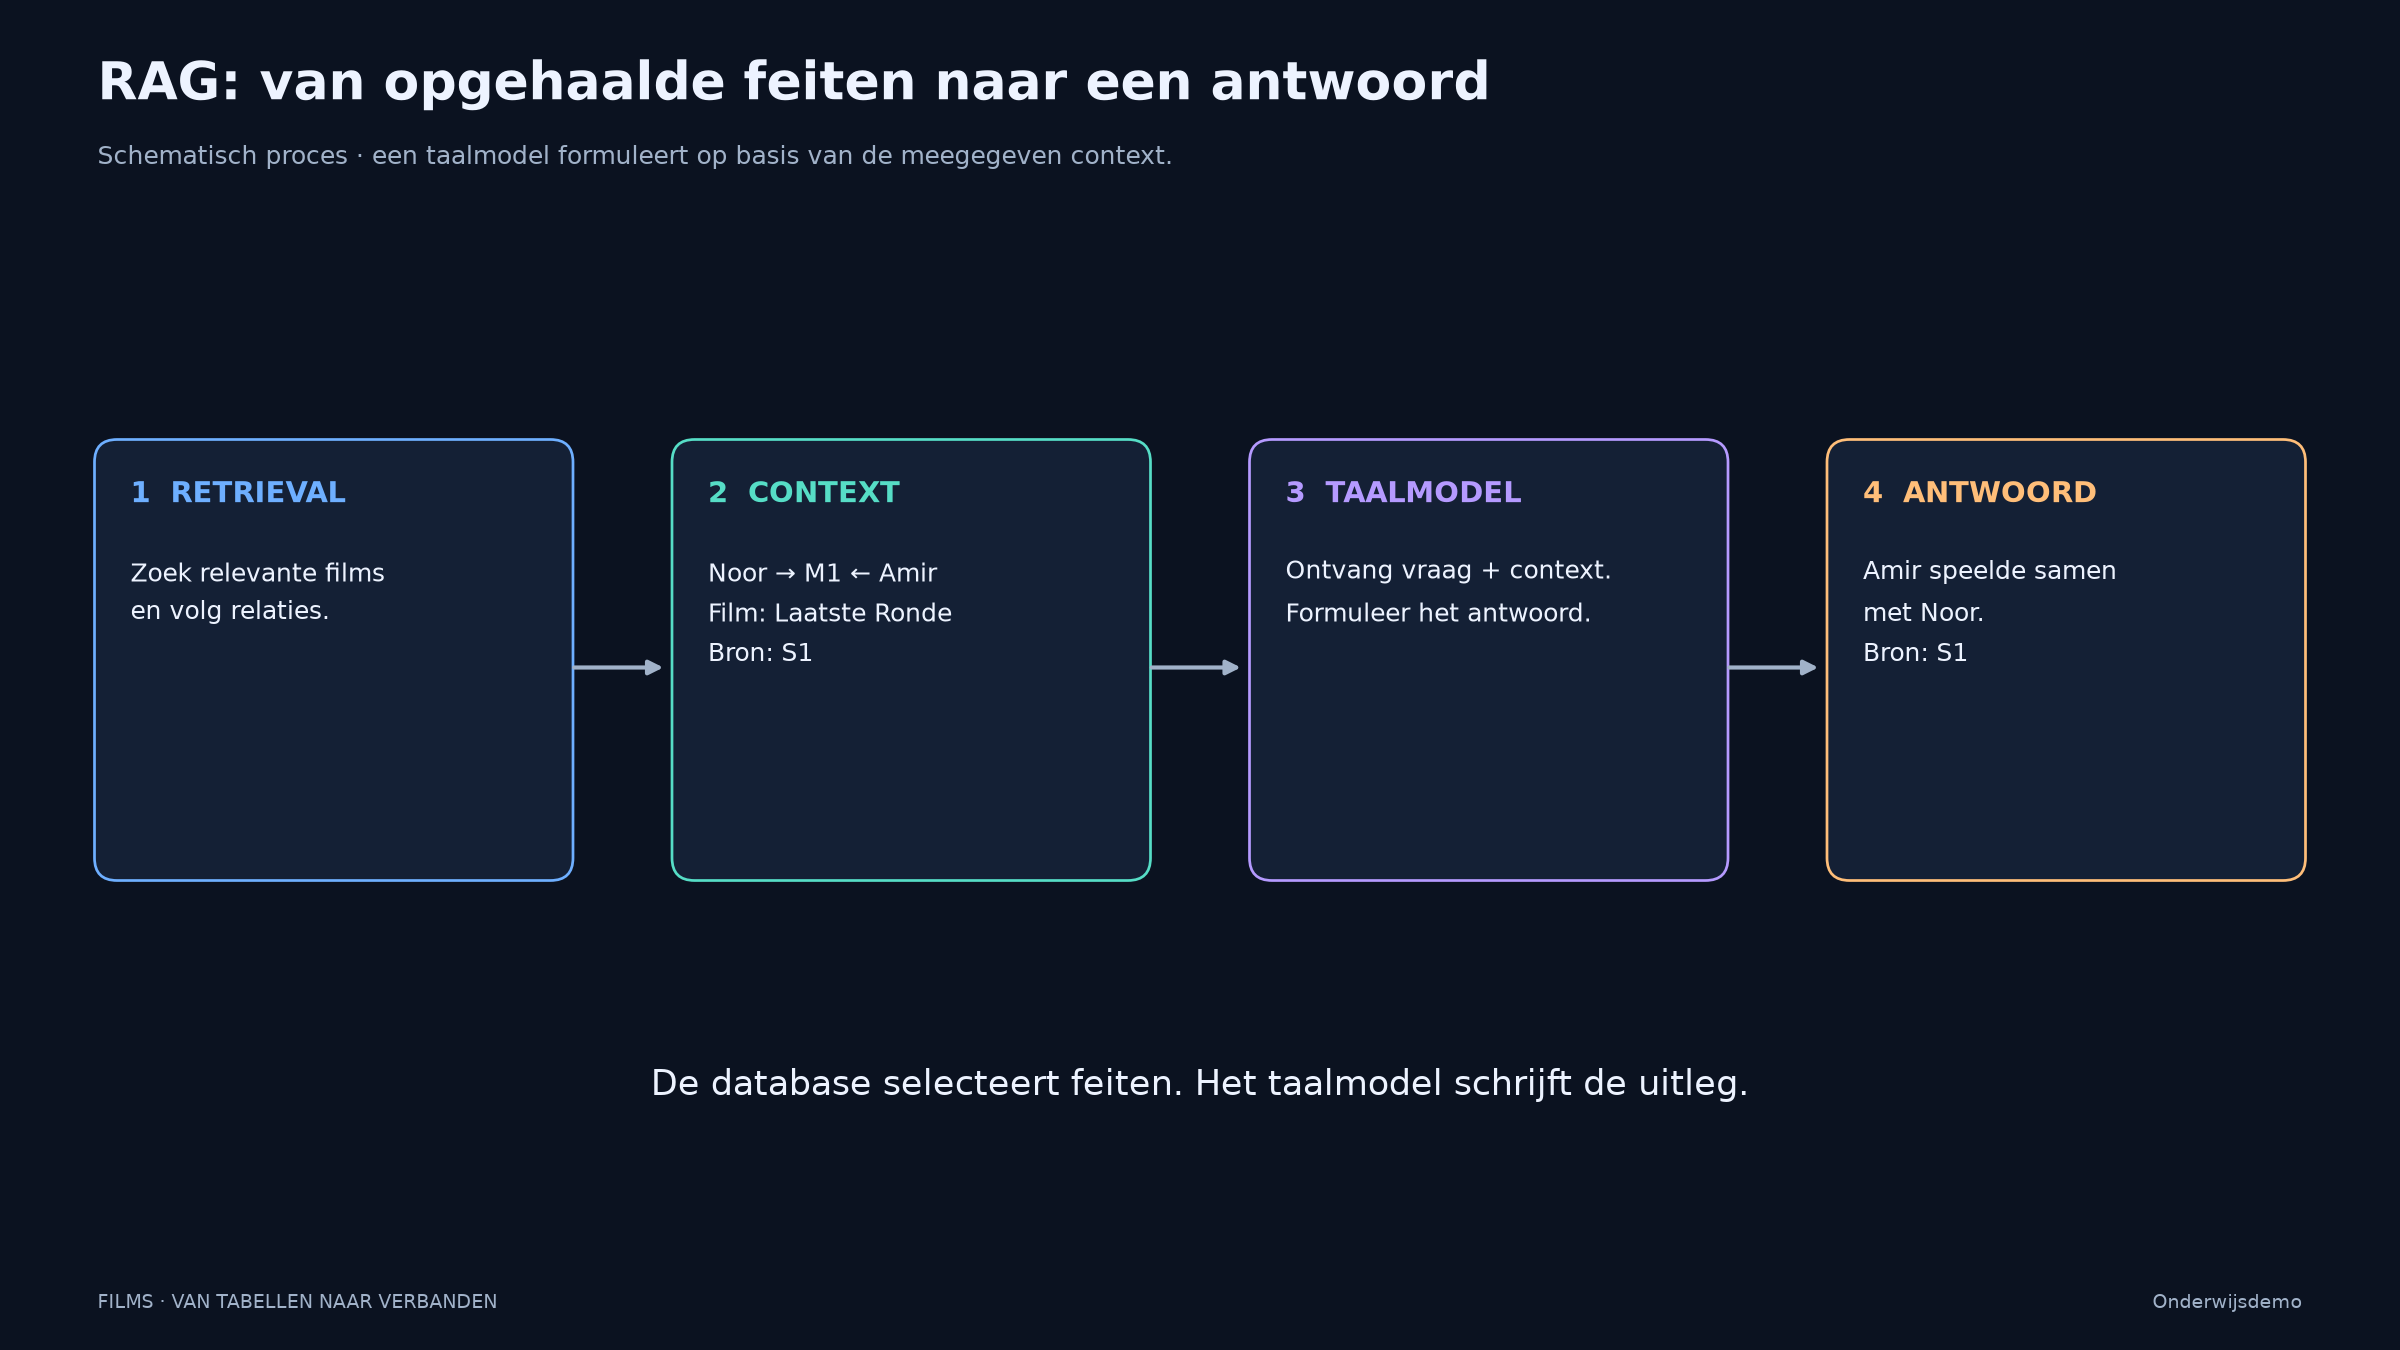

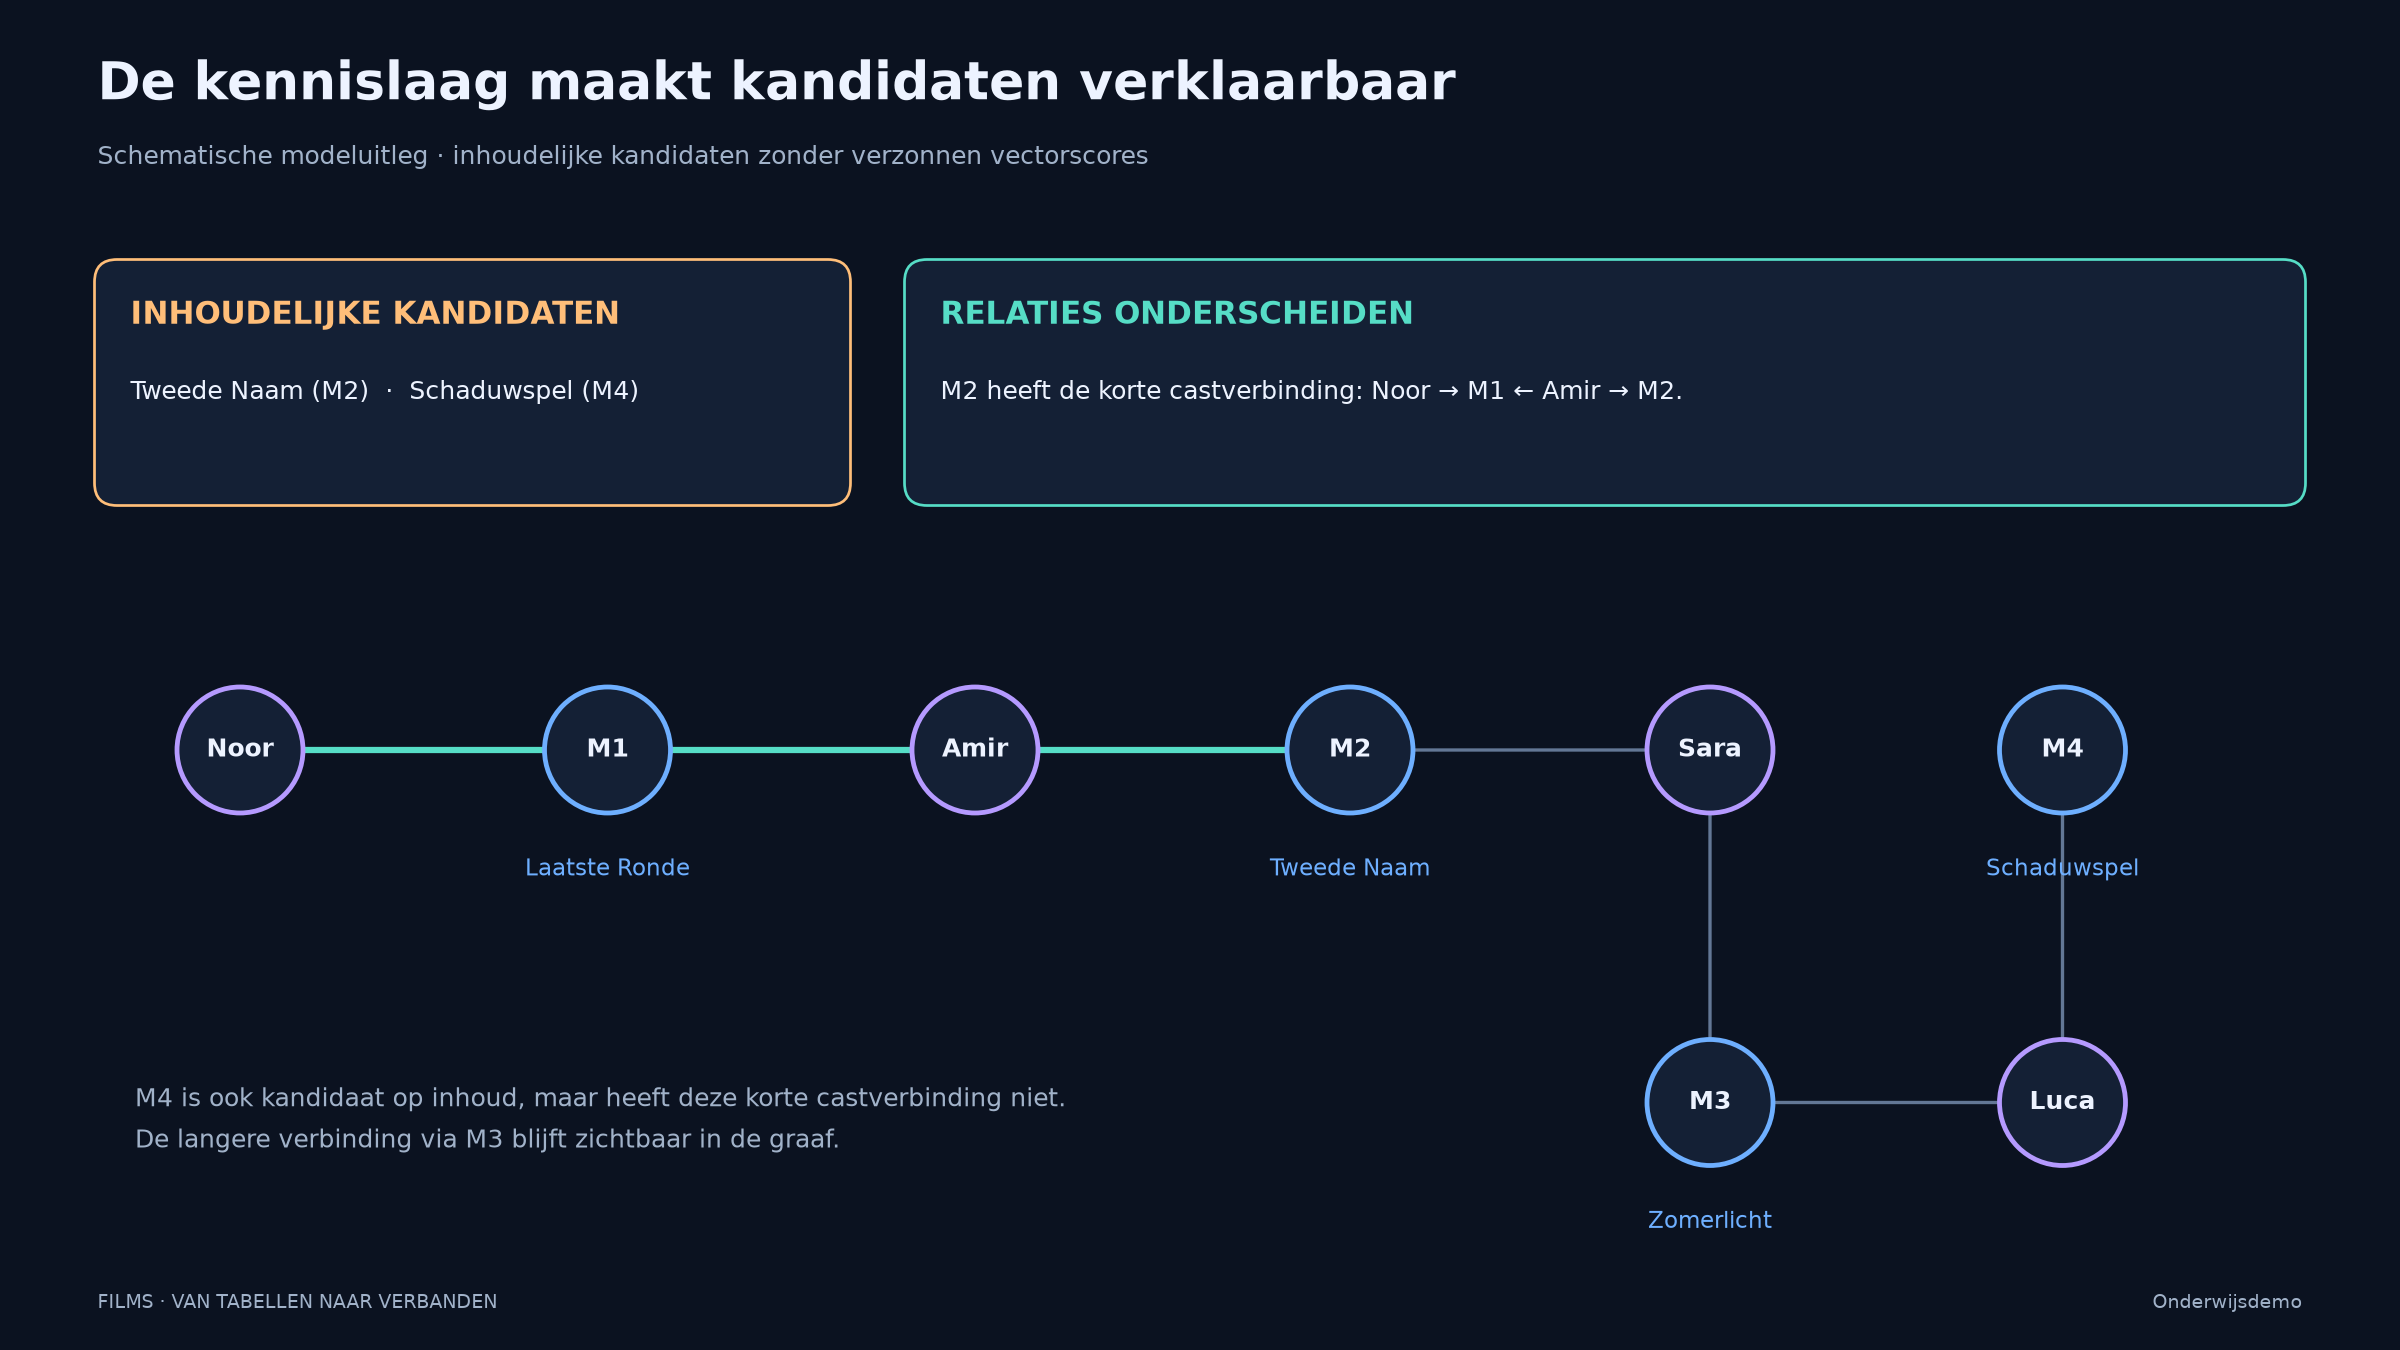

In [8]:
display(Image(filename='assets/rag.png'))
display(Image(filename='assets/kennislaag.png'))

# 5. Embeddings, indexen en zoekoppervlak

De voorbereiding maakt één echte embedding per film uit **uitsluitend de ongewijzigde `Movie.samenvatting`**.
Geen titel, genre, cast, `Person.name` of `ACTED_IN`-relatie wordt daarin samengevoegd.
`Movie.embedding` bewaart de vector; `film_vector` indexeert geschikte embeddings op `Movie`.
`movie_text` doorzoekt afzonderlijk `Movie.title` en `Movie.samenvatting`.

De lokale route gebruikt **EmbeddingGemma** via Ollama, een meertalig embeddingmodel dat Nederlandse tekst ondersteunt.
Documenten en vragen gebruiken hetzelfde model en dezelfde ruwe-tekst-aanpak. De modelnaam, modeldigest en dimensie worden gecontroleerd.
We voegen geen taakprefixen toe: dat houdt de embeddinginput exact gelijk aan het gevraagde veld. Dit is geen claim dat die
instelling de beste retrievalkwaliteit oplevert. De officiële modelkaart bespreekt taakprefixen voor andere configuraties.

Een index genereert zelf geen embeddings. De originele tekst blijft nodig voor leesbare LLM-context.
Een teruggegeven `title` maakt die titel niet alsnog onderdeel van de embedding.

film,dimensie,model,digest
M1,768,embeddinggemma:latest,85462619ee721b466c5927d109d4cb765861907d5417b9109caebc4e614679f1
M2,768,embeddinggemma:latest,85462619ee721b466c5927d109d4cb765861907d5417b9109caebc4e614679f1
M3,768,embeddinggemma:latest,85462619ee721b466c5927d109d4cb765861907d5417b9109caebc4e614679f1
M4,768,embeddinggemma:latest,85462619ee721b466c5927d109d4cb765861907d5417b9109caebc4e614679f1


name,type,labelsOrTypes,properties,state
film_vector,VECTOR,['Movie'],['embedding'],ONLINE
movie_text,FULLTEXT,['Movie'],"['title', 'samenvatting']",ONLINE


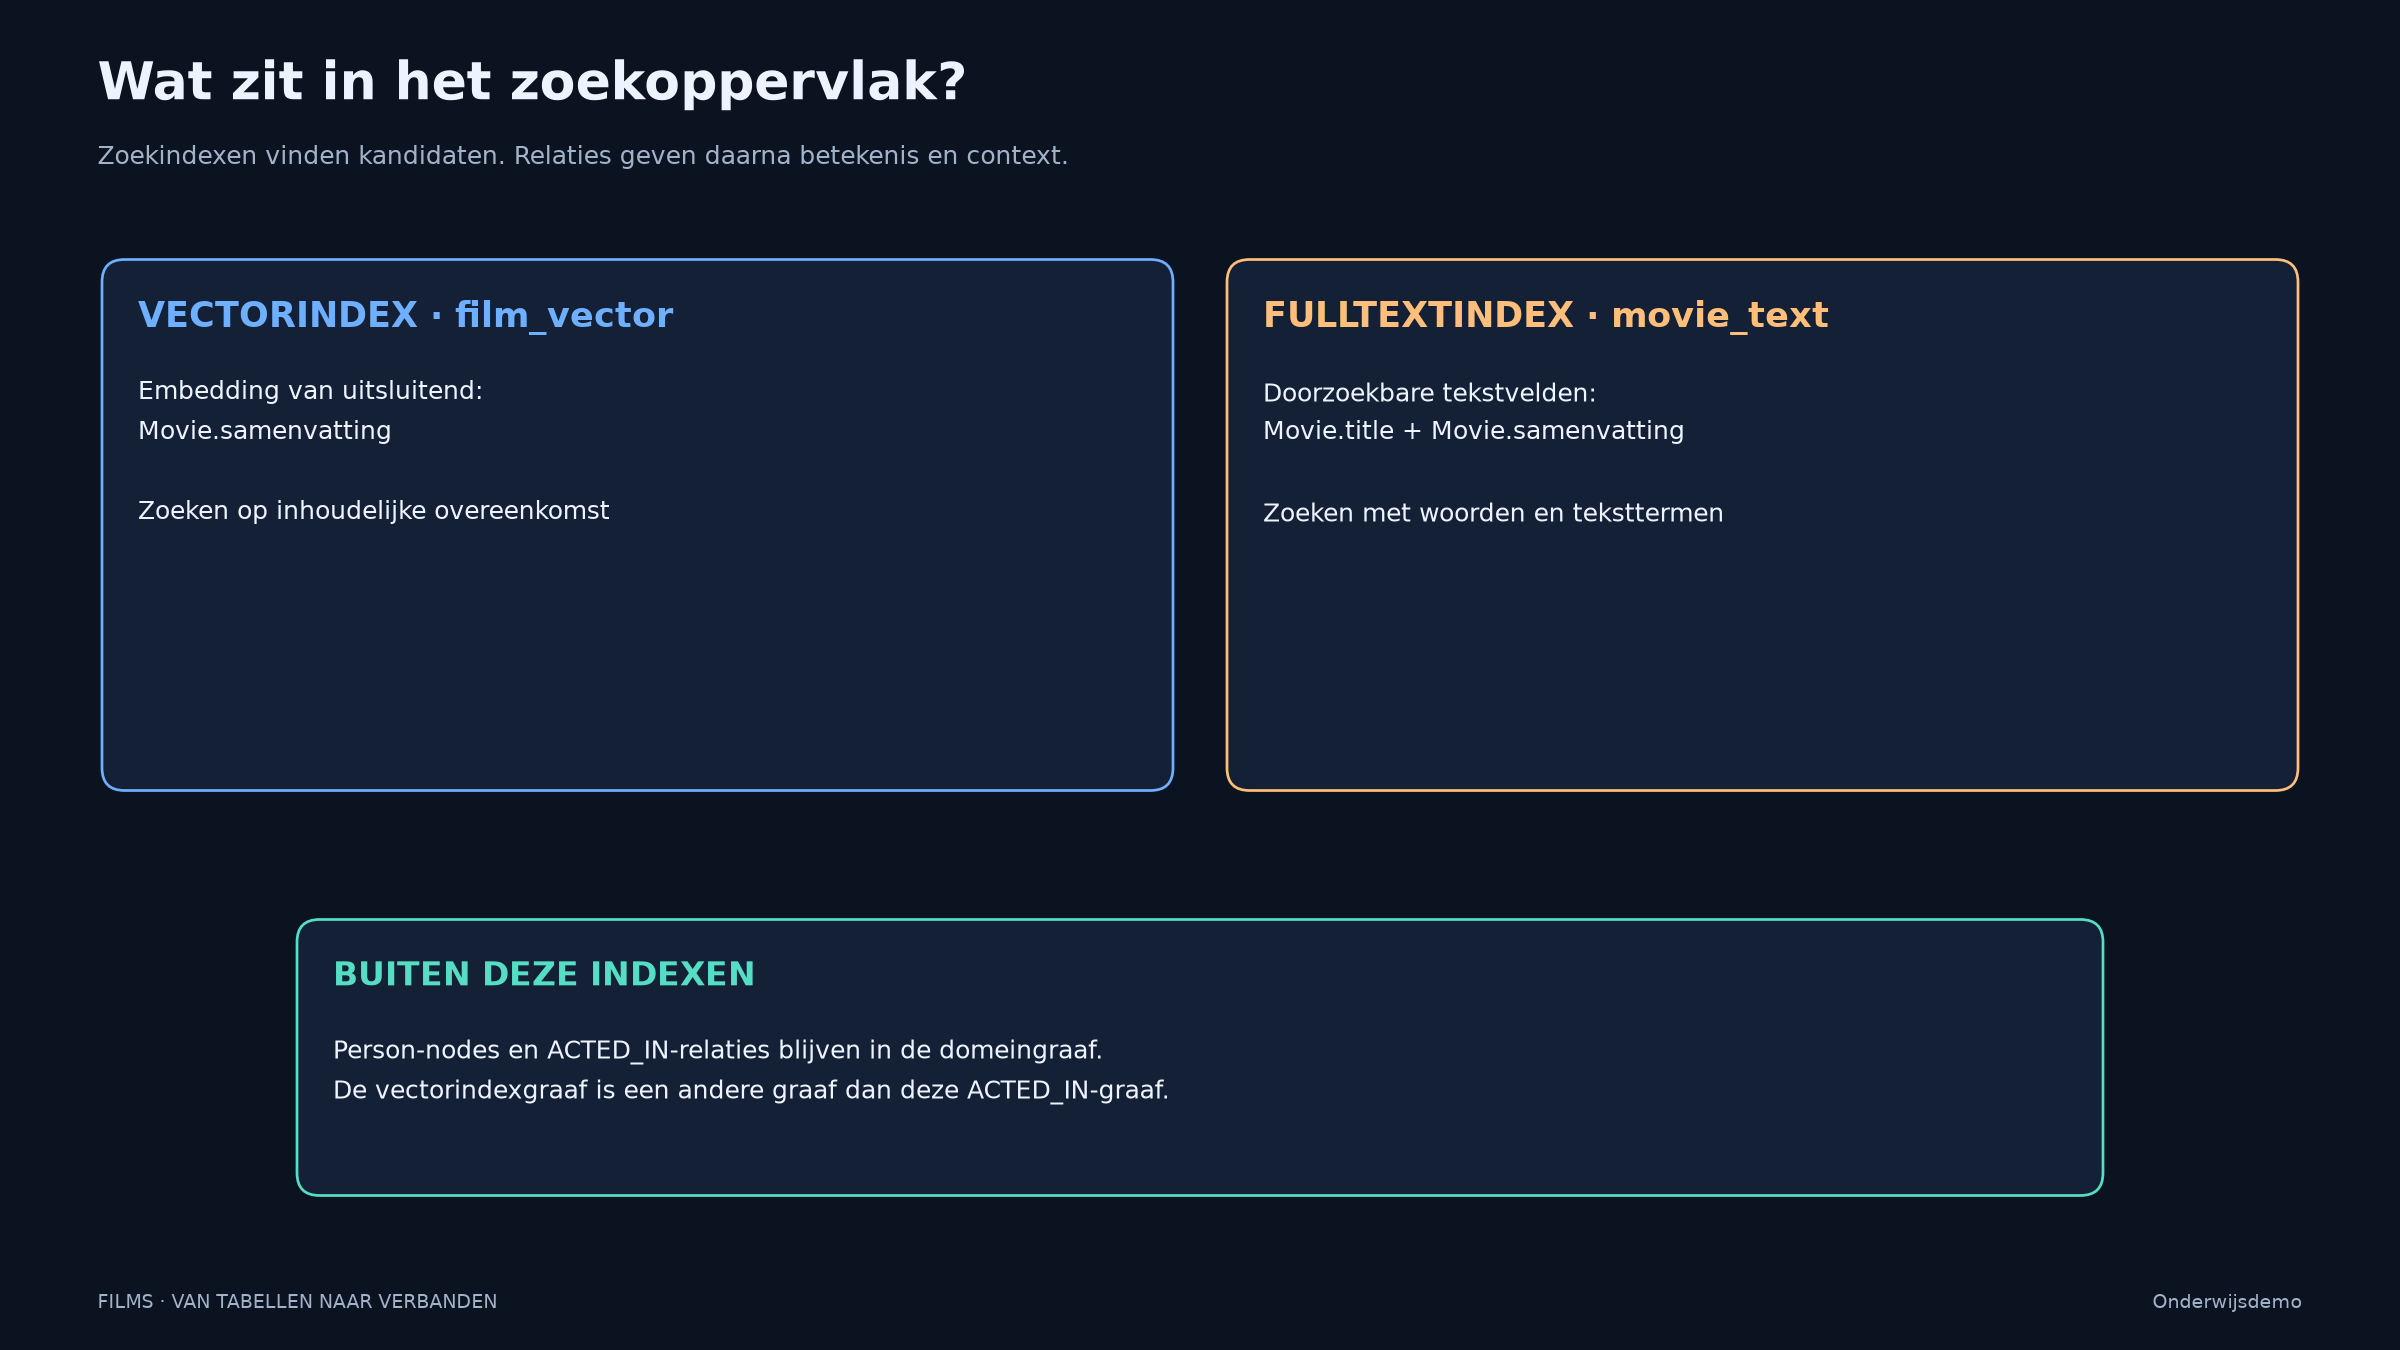

In [9]:
with graph(config) as driver:
    zoekcontrole = check_embeddings(config, driver)
table(zoekcontrole['films'])
table([{k:r[k] for k in ['name','type','labelsOrTypes','properties','state']} for r in zoekcontrole['indexen']])
display(Image(filename='assets/zoekoppervlak.png'))

### Vectorindexgraaf ≠ domeingraaf

NSW staat voor **Navigable Small World**. Korte buurverbindingen en enkele langere verbindingen helpen bij het navigeren tussen vectoren.
Een skiplist voegt niveaus toe om stappen in een lijst over te slaan. HNSW gebruikt een verwant hiërarchisch idee,
maar met nabijheidsgrafen op meerdere niveaus. Ieder punt op een hoger niveau komt ook in de lagere niveaus voor.

Deze illustratie is **schematisch**, niet een inspectie van de echte index. De nabijheidsverbindingen van een vectorindex
betekenen iets anders dan een expliciet filmfeit als `ACTED_IN`. Benaderend zoeken kan verschillen van exacte rangschikking.

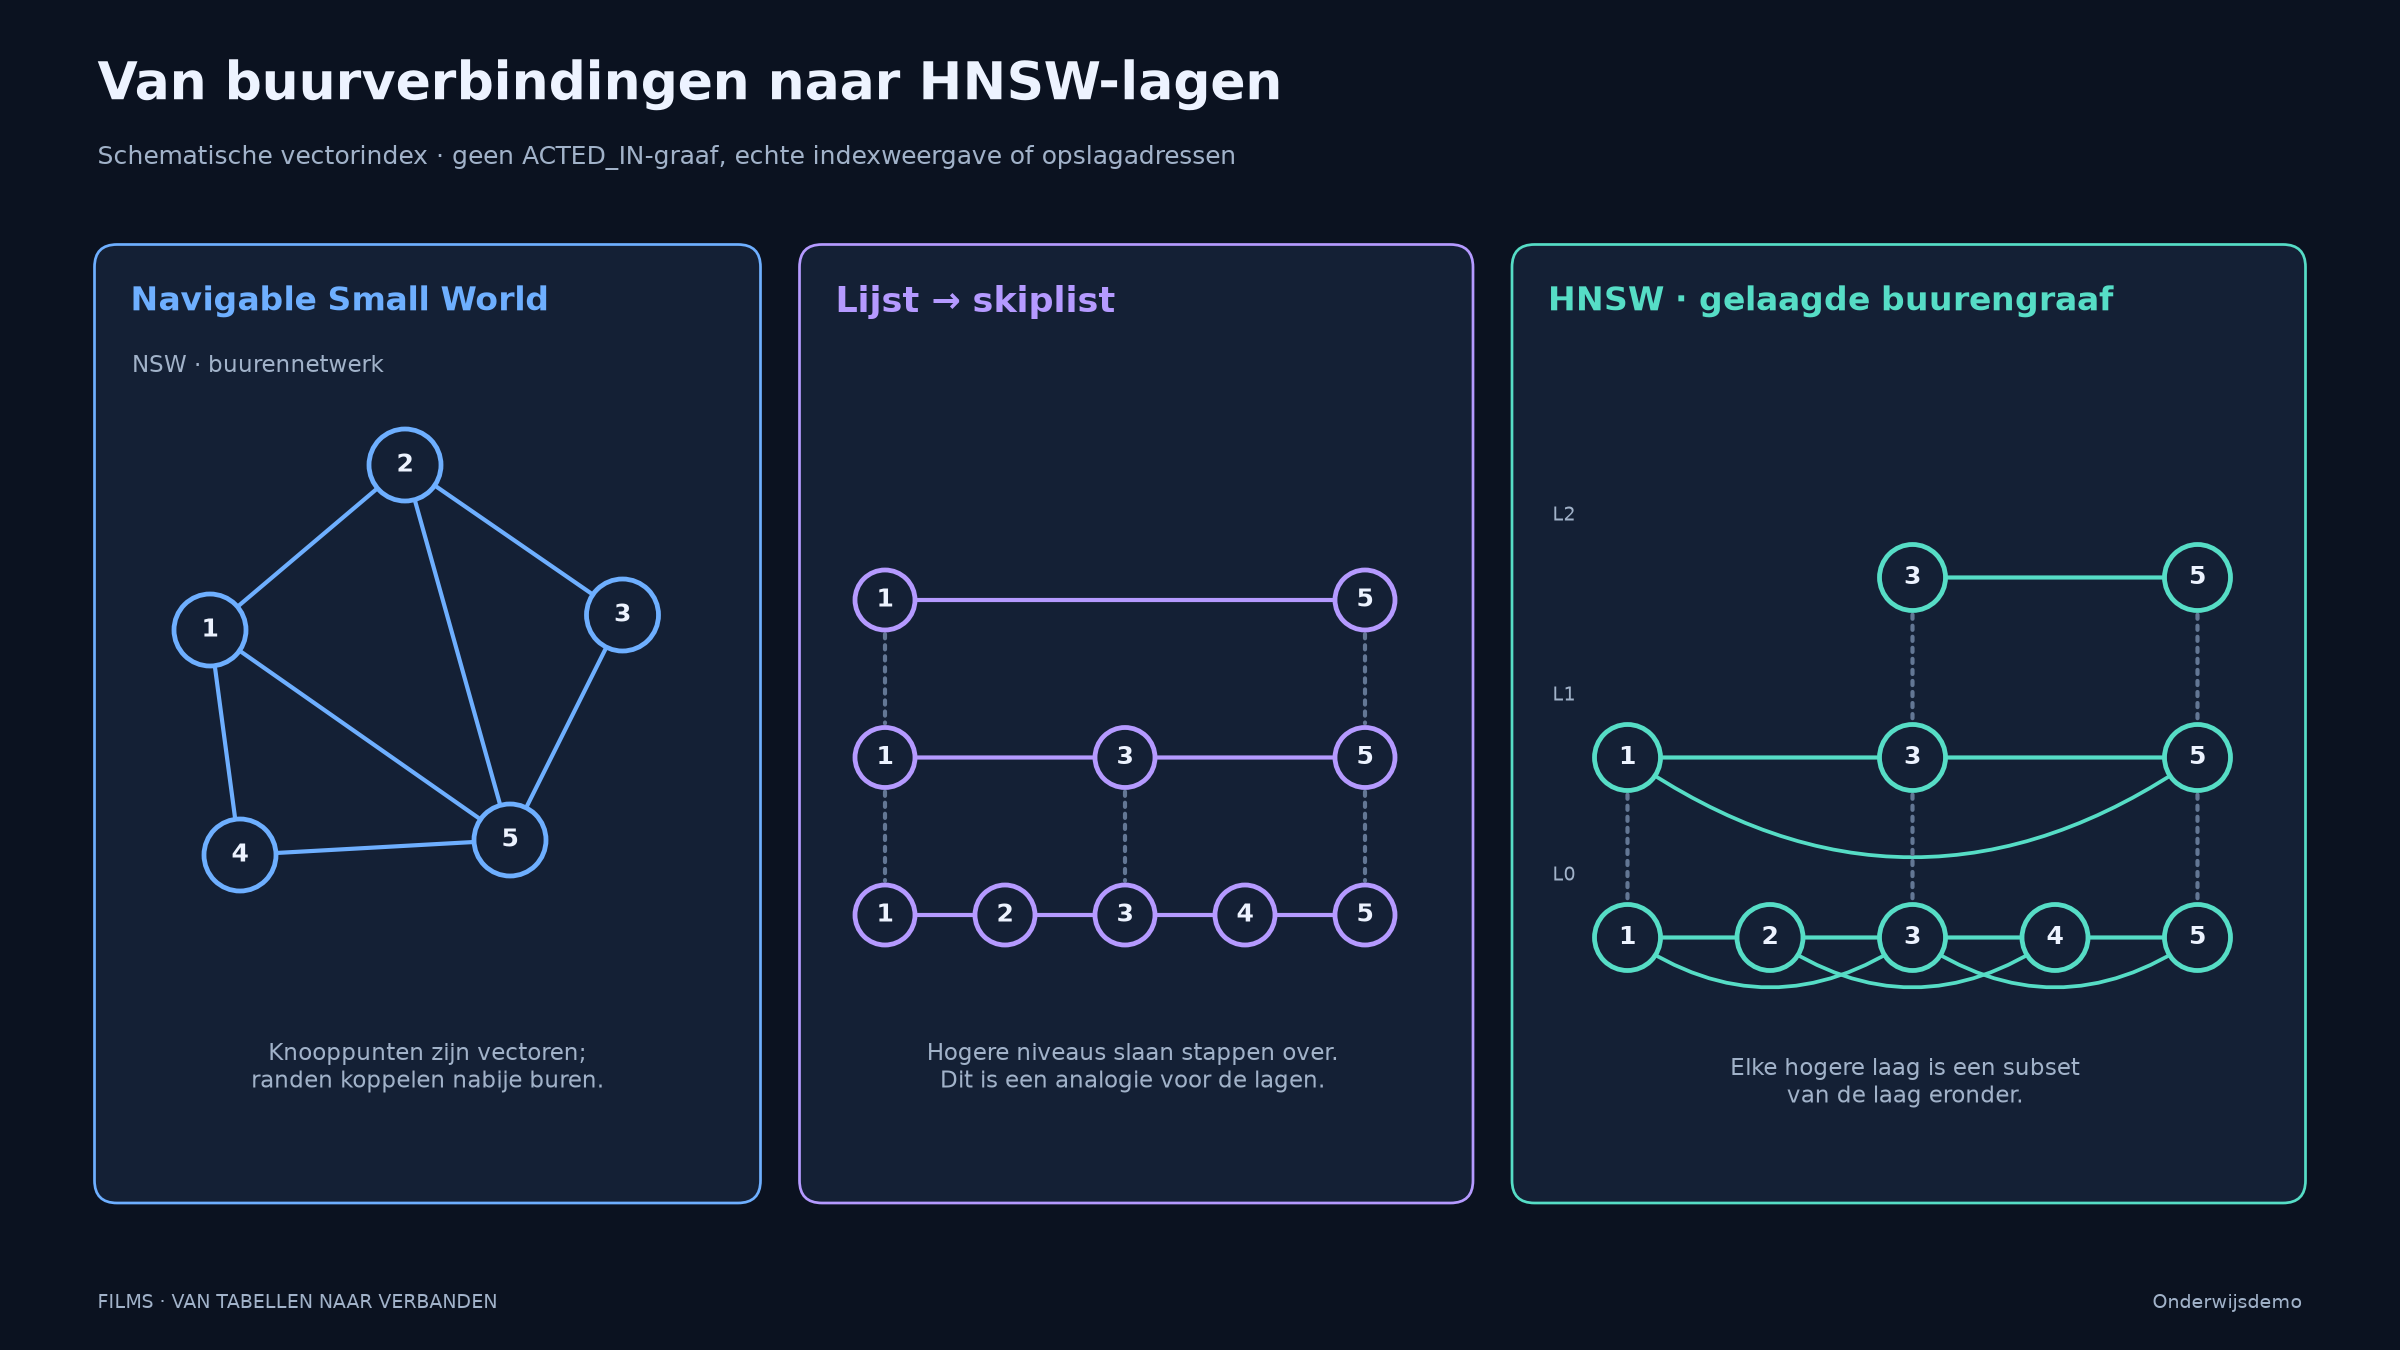

In [10]:
display(Image(filename='assets/hnsw.png'))

# 6. De vijf retrievalroutes werkelijk uitvoeren

De vijf routes gebruiken de officiële package `neo4j-graphrag`. De modelcalls hieronder zijn **echt** en lokaal,
geen handgeschreven voorbeeldantwoorden. Dit kan enkele minuten duren. Met opgeslagen outputs hoeft een lezer niets uit te voeren.

We gebruiken `top_k=2`: twee kandidaten uit de vier films. De ranking en scores komen van de echte zoekmethoden;
we selecteren geen vaste film-ID's en forceren geen volgorde. Een kleine top-k kan relevant bewijs missen;
deze keuze is geen kwaliteitsgarantie voor andere vragen of een grotere catalogus.

| Route | Vraag | Zoekoppervlak | Relatiecontrole |
|---|---|---|---|
| Vector | B | `film_vector`: embeddings van samenvattingen | Geen |
| Hybrid | B | Vectorindex plus `movie_text` | Geen |
| VectorCypher | C | Vectorresultaten, daarna ingestelde Cypher | Via acteur en gedeelde film naar Noor |
| HybridCypher | C | Vector- en full-textkandidaten, daarna ingestelde Cypher | Dezelfde voorwaarde |
| Text2Cypher | A | Door het LLM gegenereerde leesquery | Zoals werkelijk gegenereerd |

`return_properties` bepaalt alleen de uitvoervelden. **Indexkeuze, embeddinginput, propertyfilters,
relatievoorwaarden en teruggegeven velden zijn vijf verschillende dingen.**

In [11]:
from retrieval import retrieve_all
with graph(config) as driver:  # Beperkt leesaccount, óók voor gegenereerde queries.
    opgehaald = retrieve_all(config, driver)
print('Alle vijf routes en de aanvullende filter-/contextvergelijking zijn echt uitgevoerd.')

Filter properties ['genre'] not declared as filterable on index 'film_vector'; falling back to procedure-based vector search. Recreate the index with filterable_properties to use in-index filtering.


Alle vijf routes en de aanvullende filter-/contextvergelijking zijn echt uitgevoerd.


## 6.1 VectorRetriever — vraag B

Deze route zoekt met een vraagembedding tussen `Movie.embedding`-vectoren via `film_vector`.
De getoonde indexscore is geen waarschijnlijkheid dat een antwoord waar is. Castrelaties worden niet automatisch opgehaald.
Hieronder zie je eerst de werkelijke kandidaten en score, daarna de echte query en parameters.
Lange vectorarrays zijn alleen in de **weergave** ingekort tot hun dimensie; de zoekvector is niet gewijzigd.

In [12]:
route_overview(opgehaald['routes']['Vector'])
route_answer(opgehaald['routes']['Vector'])

genre,movie_id,samenvatting,score,source_id,title
thriller,M4,Een koerier ontdekt dat iemand zijn identiteit gebruikt. Hij neemt zelf een andere naam aan om de dader te vinden en raakt steeds verder verstrikt in een leven dat niet van hem is.,0.7517247200012207,S4,Schaduwspel
thriller,M2,"Een vrouw bouwt na een vlucht een nieuw leven op onder andermans naam. Wanneer haar verleden opduikt, moet ze kiezen tussen haar aangenomen identiteit en de waarheid.",0.7513083815574646,S2,Tweede Naam


**Werkelijk uitgevoerde zoekquery of queryketen**

```cypher
CYPHER 25 MATCH (node:`Movie`) SEARCH node IN (VECTOR INDEX `film_vector` FOR $query_vector LIMIT $top_k * $effective_search_ratio) SCORE AS score WITH node, score ORDER BY score DESC LIMIT $top_k RETURN node {.movie_id, .title, .genre, .samenvatting, .source_id} AS node, labels(node) AS nodeLabels, elementId(node) AS elementId, elementId(node) AS id, score
```

{
  "top_k": 2,
  "effective_search_ratio": 1,
  "vector_index_name": "film_vector",
  "query_vector": {
    "vector_dimensie": 768,
    "weergave": "vectorwaarden weggelaten; geen wijziging van zoekvector"
  }
}


**Exacte context voor de antwoordgenerator**

{"genre": "thriller", "movie_id": "M4", "samenvatting": "Een koerier ontdekt dat iemand zijn identiteit gebruikt. Hij neemt zelf een andere naam aan om de dader te vinden en raakt steeds verder verstrikt in een leven dat niet van hem is.", "score": 0.7517247200012207, "source_id": "S4", "title": "Schaduwspel"}
{"genre": "thriller", "movie_id": "M2", "samenvatting": "Een vrouw bouwt na een vlucht een nieuw leven op onder andermans naam. Wanneer haar verleden opduikt, moet ze kiezen tussen haar aangenomen identiteit en de waarheid.", "score": 0.7513083815574646, "source_id": "S2", "title": "Tweede Naam"}


**Werkelijk gegenereerd antwoord**

De films "Schaduwspel" en "Tweede Naam" gaan over iemand die onder een andere identiteit leeft.

In "Schaduwspel" neemt een koerier een andere naam aan om de dader te vinden die zijn identiteit gebruikt [S4]. In "Tweede Naam" bouwt een vrouw een nieuw leven op onder andermans naam na een vlucht [S2].

## 6.2 HybridRetriever — vraag B

Deze route combineert betekenis en woorden. In de geteste package gebruikt de standaardranker `naive`:
per zoekbranch delen door de hoogste score van die branch, daarna per film de hoogste genormaliseerde score nemen,
sorteren en top-k kiezen. **Dit is geen reciprocal rank fusion en geen waarheidskans.**
De werkelijke samengestelde query hieronder toont deze combinatie. Deze package gebruikt nog
`db.index.fulltext.queryNodes` voor het full-textdeel; de geteste server markeert die procedure als vervangen door `SEARCH`.
De aanroep werkt in deze versie; volg bij upgrades de officiële compatibiliteitsdocumentatie.
Ook deze route haalt niet vanzelf castverbindingen op.

In [13]:
route_overview(opgehaald['routes']['Hybrid'])
route_answer(opgehaald['routes']['Hybrid'])

genre,movie_id,samenvatting,score,source_id,title
thriller,M4,Een koerier ontdekt dat iemand zijn identiteit gebruikt. Hij neemt zelf een andere naam aan om de dader te vinden en raakt steeds verder verstrikt in een leven dat niet van hem is.,1.0,S4,Schaduwspel
thriller,M2,"Een vrouw bouwt na een vlucht een nieuw leven op onder andermans naam. Wanneer haar verleden opduikt, moet ze kiezen tussen haar aangenomen identiteit en de waarheid.",0.999446155710091,S2,Tweede Naam


**Werkelijk uitgevoerde zoekquery of queryketen**

```cypher
CYPHER 25 CALL () { MATCH (node:`Movie`) SEARCH node IN (VECTOR INDEX `film_vector` FOR $query_vector LIMIT $top_k * $effective_search_ratio) SCORE AS score WITH collect({node:node, score:score}) AS nodes, max(score) AS vector_index_max_score UNWIND nodes AS n RETURN n.node AS node, (n.score / vector_index_max_score) AS score UNION CALL db.index.fulltext.queryNodes($fulltext_index_name, $query_text, {limit: $top_k}) YIELD node, score WITH collect({node:node, score:score}) AS nodes, max(score) AS ft_index_max_score UNWIND nodes AS n RETURN n.node AS node, (n.score / ft_index_max_score) AS score } WITH node, max(score) AS score ORDER BY score DESC LIMIT $top_k RETURN node {.movie_id, .title, .genre, .samenvatting, .source_id} AS node, labels(node) AS nodeLabels, elementId(node) AS elementId, elementId(node) AS id, score
```

{
  "query_text": "Welke films gaan over iemand die onder een andere identiteit leeft? Leg uit waarom.",
  "top_k": 2,
  "effective_search_ratio": 1,
  "vector_index_name": "film_vector",
  "fulltext_index_name": "movie_text",
  "query_vector": {
    "vector_dimensie": 768,
    "weergave": "vectorwaarden weggelaten; geen wijziging van zoekvector"
  }
}


**Exacte context voor de antwoordgenerator**

{"genre": "thriller", "movie_id": "M4", "samenvatting": "Een koerier ontdekt dat iemand zijn identiteit gebruikt. Hij neemt zelf een andere naam aan om de dader te vinden en raakt steeds verder verstrikt in een leven dat niet van hem is.", "score": 1.0, "source_id": "S4", "title": "Schaduwspel"}
{"genre": "thriller", "movie_id": "M2", "samenvatting": "Een vrouw bouwt na een vlucht een nieuw leven op onder andermans naam. Wanneer haar verleden opduikt, moet ze kiezen tussen haar aangenomen identiteit en de waarheid.", "score": 0.999446155710091, "source_id": "S2", "title": "Tweede Naam"}


**Werkelijk gegenereerd antwoord**

De films "Schaduwspel" en "Tweede Naam" gaan over iemand die onder een andere identiteit leeft.

In "Schaduwspel" neemt een koerier een andere naam aan om de dader te vinden die zijn identiteit steelt [S4]. In "Tweede Naam" bouwt een vrouw een nieuw leven op onder andermans naam na een vlucht [S2].

## 6.3 VectorCypherRetriever — vraag C

De vectorzoekactie levert kandidaten. **Daarna** controleert een vaste vervolgquery de relatievoorwaarde.
Deze Cypher is door de ontwikkelaar ingesteld in [queries/verrijking.cypher](queries/verrijking.cypher);
het LLM bedenkt deze query niet automatisch. De contextformatter zet de opgehaalde relatiekolommen ook om
in expliciete bronfeiten. Dat is een leesbare weergave van database-uitvoer, geen handgeschreven modelantwoord.

Eerst de echte kandidaten voor C, vóór de relatiecontrole:

In [14]:
table([json.loads(i['content']) for i in opgehaald['kandidaten_vraag_C']['Vector']['items']])
display(Markdown('```cypher\n'+query('verrijking.cypher')+'\n```'))
route_overview(opgehaald['routes']['VectorCypher'])
route_answer(opgehaald['routes']['VectorCypher'])

genre,movie_id,samenvatting,score,source_id,title
thriller,M2,"Een vrouw bouwt na een vlucht een nieuw leven op onder andermans naam. Wanneer haar verleden opduikt, moet ze kiezen tussen haar aangenomen identiteit en de waarheid.",0.7314444780349731,S2,Tweede Naam
thriller,M4,Een koerier ontdekt dat iemand zijn identiteit gebruikt. Hij neemt zelf een andere naam aan om de dader te vinden en raakt steeds verder verstrikt in een leven dat niet van hem is.,0.7253506779670715,S4,Schaduwspel


```cypher
MATCH (noor:Person {person_id: $noor_id})-[:ACTED_IN]->(gedeeld:Movie)
      <-[:ACTED_IN]-(acteur:Person)-[:ACTED_IN]->(node)
WHERE acteur <> noor
RETURN node.movie_id AS movie_id, node.title AS title,
       node.samenvatting AS samenvatting, node.source_id AS source_id,
       score, acteur.name AS acteur, acteur.person_id AS acteur_id,
       gedeeld.title AS gedeelde_film, gedeeld.movie_id AS gedeelde_film_id,
       gedeeld.source_id AS gedeelde_bron, noor.name AS noor
ORDER BY score DESC, movie_id, acteur_id
```

acteur,acteur_id,gedeelde_bron,gedeelde_film,gedeelde_film_id,movie_id,noor,relatiebewijs,samenvatting,score,source_id,title
Amir,P28,S1,Laatste Ronde,M1,M2,Noor,"['Amir speelt in Tweede Naam [S2].', 'Amir en Noor spelen beiden in Laatste Ronde [S1].']","Een vrouw bouwt na een vlucht een nieuw leven op onder andermans naam. Wanneer haar verleden opduikt, moet ze kiezen tussen haar aangenomen identiteit en de waarheid.",0.7314444780349731,S2,Tweede Naam


**Werkelijk uitgevoerde zoekquery of queryketen**

```cypher
CYPHER 25 MATCH (node:`Movie`) SEARCH node IN (VECTOR INDEX `film_vector` FOR $query_vector LIMIT $top_k * $effective_search_ratio) SCORE AS score WITH node, score ORDER BY score DESC LIMIT $top_k MATCH (noor:Person {person_id: $noor_id})-[:ACTED_IN]->(gedeeld:Movie)
      <-[:ACTED_IN]-(acteur:Person)-[:ACTED_IN]->(node)
WHERE acteur <> noor
RETURN node.movie_id AS movie_id, node.title AS title,
       node.samenvatting AS samenvatting, node.source_id AS source_id,
       score, acteur.name AS acteur, acteur.person_id AS acteur_id,
       gedeeld.title AS gedeelde_film, gedeeld.movie_id AS gedeelde_film_id,
       gedeeld.source_id AS gedeelde_bron, noor.name AS noor
ORDER BY score DESC, movie_id, acteur_id
```

{
  "top_k": 2,
  "effective_search_ratio": 1,
  "vector_index_name": "film_vector",
  "query_vector": {
    "vector_dimensie": 768,
    "weergave": "vectorwaarden weggelaten; geen wijziging van zoekvector"
  },
  "noor_id": "P27"
}


**Exacte context voor de antwoordgenerator**

{"acteur": "Amir", "acteur_id": "P28", "gedeelde_bron": "S1", "gedeelde_film": "Laatste Ronde", "gedeelde_film_id": "M1", "movie_id": "M2", "noor": "Noor", "relatiebewijs": ["Amir speelt in Tweede Naam [S2].", "Amir en Noor spelen beiden in Laatste Ronde [S1]."], "samenvatting": "Een vrouw bouwt na een vlucht een nieuw leven op onder andermans naam. Wanneer haar verleden opduikt, moet ze kiezen tussen haar aangenomen identiteit en de waarheid.", "score": 0.7314444780349731, "source_id": "S2", "title": "Tweede Naam"}


**Werkelijk gegenereerd antwoord**

De film die hieraan voldoet is Tweede Naam.

De film gaat over een vrouw die een nieuw leven opbouwt onder andermans naam [S2]. De acteur Amir speelt in deze film [S2] en hij heeft met Noor samengespeeld in de film Laatste Ronde [S1].

## 6.4 HybridCypherRetriever — vraag C

Eerst vector- en woordkandidaten combineren, daarna **dezelfde ingestelde relatievoorwaarde**.
Die vervolgquery werkt na kandidaatselectie: hij kan rijen verwijderen of uitbreiden, maar geen film terughalen
die niet in de kandidaten zat. Bij een kleine top-k kan relevant relatiebewijs dus buiten beeld blijven.

In [15]:
table([json.loads(i['content']) for i in opgehaald['kandidaten_vraag_C']['Hybrid']['items']])
route_overview(opgehaald['routes']['HybridCypher'])
route_answer(opgehaald['routes']['HybridCypher'])

genre,movie_id,samenvatting,score,source_id,title
thriller,M2,"Een vrouw bouwt na een vlucht een nieuw leven op onder andermans naam. Wanneer haar verleden opduikt, moet ze kiezen tussen haar aangenomen identiteit en de waarheid.",1.0,S2,Tweede Naam
thriller,M4,Een koerier ontdekt dat iemand zijn identiteit gebruikt. Hij neemt zelf een andere naam aan om de dader te vinden en raakt steeds verder verstrikt in een leven dat niet van hem is.,1.0,S4,Schaduwspel


acteur,acteur_id,gedeelde_bron,gedeelde_film,gedeelde_film_id,movie_id,noor,relatiebewijs,samenvatting,score,source_id,title
Amir,P28,S1,Laatste Ronde,M1,M2,Noor,"['Amir speelt in Tweede Naam [S2].', 'Amir en Noor spelen beiden in Laatste Ronde [S1].']","Een vrouw bouwt na een vlucht een nieuw leven op onder andermans naam. Wanneer haar verleden opduikt, moet ze kiezen tussen haar aangenomen identiteit en de waarheid.",1.0,S2,Tweede Naam


**Werkelijk uitgevoerde zoekquery of queryketen**

```cypher
CYPHER 25 CALL () { MATCH (node:`Movie`) SEARCH node IN (VECTOR INDEX `film_vector` FOR $query_vector LIMIT $top_k * $effective_search_ratio) SCORE AS score WITH collect({node:node, score:score}) AS nodes, max(score) AS vector_index_max_score UNWIND nodes AS n RETURN n.node AS node, (n.score / vector_index_max_score) AS score UNION CALL db.index.fulltext.queryNodes($fulltext_index_name, $query_text, {limit: $top_k}) YIELD node, score WITH collect({node:node, score:score}) AS nodes, max(score) AS ft_index_max_score UNWIND nodes AS n RETURN n.node AS node, (n.score / ft_index_max_score) AS score } WITH node, max(score) AS score ORDER BY score DESC LIMIT $top_k MATCH (noor:Person {person_id: $noor_id})-[:ACTED_IN]->(gedeeld:Movie)
      <-[:ACTED_IN]-(acteur:Person)-[:ACTED_IN]->(node)
WHERE acteur <> noor
RETURN node.movie_id AS movie_id, node.title AS title,
       node.samenvatting AS samenvatting, node.source_id AS source_id,
       score, acteur.name AS acteur, acteur.person_id AS acteur_id,
       gedeeld.title AS gedeelde_film, gedeeld.movie_id AS gedeelde_film_id,
       gedeeld.source_id AS gedeelde_bron, noor.name AS noor
ORDER BY score DESC, movie_id, acteur_id
```

{
  "query_text": "Welke film gaat over iemand die onder een andere identiteit leeft én heeft een acteur die met Noor samenspeelde? Onderbouw je antwoord.",
  "top_k": 2,
  "effective_search_ratio": 1,
  "vector_index_name": "film_vector",
  "fulltext_index_name": "movie_text",
  "query_vector": {
    "vector_dimensie": 768,
    "weergave": "vectorwaarden weggelaten; geen wijziging van zoekvector"
  },
  "noor_id": "P27"
}


**Exacte context voor de antwoordgenerator**

{"acteur": "Amir", "acteur_id": "P28", "gedeelde_bron": "S1", "gedeelde_film": "Laatste Ronde", "gedeelde_film_id": "M1", "movie_id": "M2", "noor": "Noor", "relatiebewijs": ["Amir speelt in Tweede Naam [S2].", "Amir en Noor spelen beiden in Laatste Ronde [S1]."], "samenvatting": "Een vrouw bouwt na een vlucht een nieuw leven op onder andermans naam. Wanneer haar verleden opduikt, moet ze kiezen tussen haar aangenomen identiteit en de waarheid.", "score": 1.0, "source_id": "S2", "title": "Tweede Naam"}


**Werkelijk gegenereerd antwoord**

De film is Tweede Naam.

Deze film gaat over een vrouw die een nieuw leven opbouwt onder andermans naam [S2]. De acteur Amir speelt in deze film [S2] en hij heeft met Noor samengespeeld in de film Laatste Ronde [S1].

## 6.5 Text2CypherRetriever — vraag A

Deze route krijgt een vraag, schema en instructies en laat een LLM een query schrijven. **Standaard is er geen vectorzoekactie.**
Dit is ook geen full-textzoekactie: Text2Cypher vertaalt een opdracht; een full-textindex doorzoekt tekst.
Een eventueel gegenereerde `CONTAINS`-controle zou evenmin semantisch vectorzoeken zijn.

Een programmeur kan SQL schrijven op basis van tabellen en kolommen zonder alle records vooraf te zien.
Zo kan het model hier Cypher schrijven op basis van labels, properties en relaties. We geven ook de concrete binding
Noor = `P27` mee; die informatie wordt dus niet magisch uit het schema afgeleid.
De geteste package controleert met `EXPLAIN` of de gegenereerde query alleen leest. Daarnaast heeft het databaseaccount
alleen leesrechten. Er worden geen door het model gegenereerde mutaties uitgevoerd.

In [16]:
print('Exact schema voor het model:\n'+opgehaald['schema_voor_Text2Cypher'])
print('\nExacte querygeneratieprompt:\n'+opgehaald['routes']['Text2Cypher']['modelcalls'][0]['input'])
print('\nWerkelijk gegenereerde Cypher:\n'+opgehaald['routes']['Text2Cypher']['metadata']['cypher'])
route_overview(opgehaald['routes']['Text2Cypher'])
route_answer(opgehaald['routes']['Text2Cypher'])

Exact schema voor het model:
Node properties:
Person {person_id: STRING, name: STRING}
Movie {movie_id: STRING, title: STRING, genre: STRING, samenvatting: STRING, source_id: STRING, embedding: LIST<FLOAT>}
Relationships:
(:Person)-[:ACTED_IN]->(:Movie)
Constraints: Person.person_id is uniek; Movie.movie_id is uniek.
Genre is een property; er bestaat geen Genre-label.
Zakelijke identifier voor Noor in deze demo: P27. Dit is geen interne Neo4j-ID.

Exacte querygeneratieprompt:
Vertaal de vraag naar precies één leesbare Cypher-leesquery.
Gebruik alleen onderstaand schema. Geen mutaties, procedures of dynamische query-uitvoering.
Geef uitsluitend de query terug. Gebruik voor Noor person_id 'P27'.
Bij vragen naar collega's: sluit Noor uit, verwijder dubbelen en sorteer stabiel.
Retourneer precies de kolommen person_id, name, source_id, noor en gedeelde_film.
source_id is de bron-ID van de gedeelde film; noor is de naam van de startpersoon;
gedeelde_film is de titel van de gedeelde film. Zo

gedeelde_film,name,noor,person_id,relatiebewijs,source_id
Laatste Ronde,Amir,Noor,P28,['Amir en Noor spelen beiden in Laatste Ronde [S1].'],S1


**Werkelijk uitgevoerde zoekquery of queryketen**

```cypher
EXPLAIN MATCH (noor:Person {person_id: 'P27'})-[:ACTED_IN]->(m:Movie)<-[:ACTED_IN]-(collega:Person)
WHERE noor <> collega
RETURN DISTINCT collega.person_id AS person_id, collega.name AS name, m.source_id AS source_id, noor.name AS noor, m.title AS gedeelde_film
ORDER BY name, source_id

```

{}


```cypher
MATCH (noor:Person {person_id: 'P27'})-[:ACTED_IN]->(m:Movie)<-[:ACTED_IN]-(collega:Person)
WHERE noor <> collega
RETURN DISTINCT collega.person_id AS person_id, collega.name AS name, m.source_id AS source_id, noor.name AS noor, m.title AS gedeelde_film
ORDER BY name, source_id

```

{}


**Exacte context voor de antwoordgenerator**

{"gedeelde_film": "Laatste Ronde", "name": "Amir", "noor": "Noor", "person_id": "P28", "relatiebewijs": ["Amir en Noor spelen beiden in Laatste Ronde [S1]."], "source_id": "S1"}


**Werkelijk gegenereerd antwoord**

Noor speelde samen met Amir in de film "Laatste Ronde" [S1].

### Propertyfilters zijn geen relatievoorwaarden

`genre = thriller` houdt hier **M2 én M4** over en lost vraag C niet op.
In de geteste package kan VectorRetriever een `filters`-argument gebruiken. Of dat binnen de vectorindex
gebeurt of via exacte cosine-vergelijking na een metadatafilter hangt af van index/configuratie en ondersteunde operatoren.
De volgende **werkelijk uitgevoerde query** laat zien welk pad deze index koos.

Hybrid heeft in deze geteste API geen gelijkwaardig `filters`-argument. Een `WHERE` in de ingestelde
verrijkingsquery komt pas na retrieval/fusion. Filteren vóór top-k verkleint de kandidaatverzameling vóór rangschikking;
filteren ná top-k kan minder dan k resultaten overhouden en relevante kandidaten missen.
Bij het hier waargenomen exacte cosine-pad geeft filteren vóór rangschikking de beste k binnen de gefilterde
verzameling; in-index ANN blijft benaderend en garandeert niet altijd de exact beste k.

In [17]:
genre = opgehaald['genre_filter']
table([json.loads(i['content']) for i in genre['items']])
for call in genre['zoekqueries']:
    display(Markdown('```cypher\n'+call['cypher']+'\n```'))
assert {json.loads(i['content'])['movie_id'] for i in genre['items']} == {'M2','M4'}

genre,movie_id,samenvatting,score,source_id,title
thriller,M4,Een koerier ontdekt dat iemand zijn identiteit gebruikt. Hij neemt zelf een andere naam aan om de dader te vinden en raakt steeds verder verstrikt in een leven dat niet van hem is.,0.7517247200012207,S4,Schaduwspel
thriller,M2,"Een vrouw bouwt na een vlucht een nieuw leven op onder andermans naam. Wanneer haar verleden opduikt, moet ze kiezen tussen haar aangenomen identiteit en de waarheid.",0.7513083815574646,S2,Tweede Naam


```cypher
MATCH (node:`Movie`) WHERE node.`embedding` IS NOT NULL AND size(node.`embedding`) = toInteger($embedding_dimension) AND (node.genre = $param_0) WITH node, vector.similarity.cosine(node.`embedding`, $query_vector) AS score ORDER BY score DESC, elementId(node) LIMIT $top_k RETURN node {.movie_id, .title, .genre, .samenvatting, .source_id} AS node, labels(node) AS nodeLabels, elementId(node) AS elementId, elementId(node) AS id, score
```

# 7. Een onderbouwd antwoord en de kennislaag

**Het concrete probleem:** twee films passen inhoudelijk, maar slechts één heeft de gevraagde directe castverbinding.
De kennislaag organiseert dezelfde entiteiten/identifiers, de betekenis van relaties, tekst, gestructureerde feiten en herkomst.
Dit is een **logische architectuurlaag**, geen apart fysiek opslagformaat.

Voor **Tweede Naam** combineren we:

- Thema: de samenvatting in **S2**.
- Amir in Tweede Naam: de cast in **S2**.
- Amir en Noor in Laatste Ronde: de cast in **S1**.

Luca in Schaduwspel heeft in deze gegevens niet rechtstreeks met Noor samengespeeld. Er bestaat wel een langere keten
via andere personen en films. De specifieke vraag vraagt om een **gedeelde film**, niet om willekeurige bereikbaarheid.

In [18]:
for route in ['VectorCypher','HybridCypher']:
    result = opgehaald['routes'][route]
    assert {json.loads(i['content'])['movie_id'] for i in result['items']} == {'M2'}
    display(Markdown('### '+route))
    route_answer(result)

### VectorCypher

**Exacte context voor de antwoordgenerator**

{"acteur": "Amir", "acteur_id": "P28", "gedeelde_bron": "S1", "gedeelde_film": "Laatste Ronde", "gedeelde_film_id": "M1", "movie_id": "M2", "noor": "Noor", "relatiebewijs": ["Amir speelt in Tweede Naam [S2].", "Amir en Noor spelen beiden in Laatste Ronde [S1]."], "samenvatting": "Een vrouw bouwt na een vlucht een nieuw leven op onder andermans naam. Wanneer haar verleden opduikt, moet ze kiezen tussen haar aangenomen identiteit en de waarheid.", "score": 0.7314444780349731, "source_id": "S2", "title": "Tweede Naam"}


**Werkelijk gegenereerd antwoord**

De film die hieraan voldoet is Tweede Naam.

De film gaat over een vrouw die een nieuw leven opbouwt onder andermans naam [S2]. De acteur Amir speelt in deze film [S2] en hij heeft met Noor samengespeeld in de film Laatste Ronde [S1].

### HybridCypher

**Exacte context voor de antwoordgenerator**

{"acteur": "Amir", "acteur_id": "P28", "gedeelde_bron": "S1", "gedeelde_film": "Laatste Ronde", "gedeelde_film_id": "M1", "movie_id": "M2", "noor": "Noor", "relatiebewijs": ["Amir speelt in Tweede Naam [S2].", "Amir en Noor spelen beiden in Laatste Ronde [S1]."], "samenvatting": "Een vrouw bouwt na een vlucht een nieuw leven op onder andermans naam. Wanneer haar verleden opduikt, moet ze kiezen tussen haar aangenomen identiteit en de waarheid.", "score": 1.0, "source_id": "S2", "title": "Tweede Naam"}


**Werkelijk gegenereerd antwoord**

De film is Tweede Naam.

Deze film gaat over een vrouw die een nieuw leven opbouwt onder andermans naam [S2]. De acteur Amir speelt in deze film [S2] en hij heeft met Noor samengespeeld in de film Laatste Ronde [S1].

### Wat mist een gewone vectorroute bij vraag C?

Hieronder staat nog een echte RAG-call met dezelfde vectorroute maar vraag C. De context bevat wel filmteksten en bron-ID's,
maar geen castverbindingen. Beoordeel het gegenereerde antwoord op die zichtbare bewijslimiet: een correct geraden film
zou zonder ontvangen relatiebewijs nog steeds niet voldoende onderbouwd zijn.

In [19]:
route_answer(opgehaald['vector_zonder_relatiebewijs'])

**Exacte context voor de antwoordgenerator**

{"genre": "thriller", "movie_id": "M2", "samenvatting": "Een vrouw bouwt na een vlucht een nieuw leven op onder andermans naam. Wanneer haar verleden opduikt, moet ze kiezen tussen haar aangenomen identiteit en de waarheid.", "score": 0.7314444780349731, "source_id": "S2", "title": "Tweede Naam"}
{"genre": "thriller", "movie_id": "M4", "samenvatting": "Een koerier ontdekt dat iemand zijn identiteit gebruikt. Hij neemt zelf een andere naam aan om de dader te vinden en raakt steeds verder verstrikt in een leven dat niet van hem is.", "score": 0.7253506779670715, "source_id": "S4", "title": "Schaduwspel"}


**Werkelijk gegenereerd antwoord**

Er is onvoldoende bewijs om te bepalen welke film aan deze voorwaarde voldoet.

Hoewel zowel "Tweede Naam" [S2] (een vrouw die onder andermans naam leeft) als "Schaduwspel" [S4] (een koerier die een andere naam aanneemt) gaan over iemand die onder een andere identiteit leeft, bevat de verstrekte context geen informatie over acteurs of hun samenwerking met Noor. Er is dus geen bewijs voor de tweede voorwaarde.

# 8. Grenzen, reproduceerbaarheid en conclusie

- Alle vijf retrievers werken niet op dezelfde manier en zijn niet voor iedere vraag even geschikt.
- Vector- en full-textscores zijn zoeksignalen, geen waarheidsscores. Hybrid-normalisatie verandert hun betekenis.
- Een index doorzoekt alleen het ingestelde oppervlak; relaties worden niet vanzelf in tekstembeddings meegenomen.
- De vier films en twee opgehaalde kandidaten maken de les overzichtelijk; dit is geen evaluatie van retrievalkwaliteit op een grote catalogus.
- Context kan fout of onvolledig zijn en een LLM kan nog steeds verkeerde conclusies trekken. Controleer bronnen.
- De lokale modellen gebruiken temperatuur 0, maar hardware/software/indexopbouw kunnen uitvoer beïnvloeden.
  Reproduceerbaar betekent hier: dezelfde brondata, code, modeldigest en controleerbare echte uitvoering, niet gegarandeerd byte-identieke taal.
- Deze minidataset bewijst geen algemene snelheidswinst. Onderzoek grotere werkbelastingen apart.

**Bewaar de bewijsvoering:** onderstaande cel slaat de echte queryplannen, context, modelcalls en resultaten op.
Het bestand bevat applicatieprompts voor deze demo, geen ontwikkelgesprekken, wachtwoorden of privéwerkpaden.

In [20]:
import importlib.metadata as metadata
from datetime import datetime, timezone
versies = {p:metadata.version(p) for p in ['neo4j','psycopg','neo4j-graphrag','ollama','matplotlib','nbconvert','ipykernel']}
registratie = {'uitgevoerd_utc':datetime.now(timezone.utc).isoformat(),
              'omgeving':{'os':platform.system(), 'architectuur':platform.machine(), 'python':platform.python_version(),
                          'pakketten':versies, 'modelopties':{'temperature':0,'num_ctx':8192,'num_predict':400,'think':False},
                          'llm':{'naam':config['LLM_MODEL'],'digest':opgehaald['modeldigest']}},
              'datacontrole':controle, 'databases':uitslag, 'zoekindexen':zoekcontrole, 'retrieval':opgehaald}
Path('artifacts').mkdir(exist_ok=True)
Path('artifacts/uitvoering.json').write_text(json.dumps(registratie,ensure_ascii=False,indent=2),encoding='utf-8')
table([{'onderdeel':k,'versie':v} for k,v in versies.items()])
print('Alle controles geslaagd; echte uitvoer opgeslagen in artifacts/uitvoering.json.')

onderdeel,versie
neo4j,6.4.1
psycopg,3.3.6
neo4j-graphrag,1.23.0
ollama,0.6.3
matplotlib,3.11.2
nbconvert,7.17.2
ipykernel,7.4.0


Alle controles geslaagd; echte uitvoer opgeslagen in artifacts/uitvoering.json.


## Verder lezen en zelf demonstreren

[README](README.md) · [Installatie en live-demo](HANDLEIDING.md) · [Primaire bronnen](BRONNEN.md).

Gebruik live de centrale querybestanden in pgAdmin en Neo4j Desktop; gebruik dit reeds uitgevoerde notebook voor de
RAG-context en de visuele toelichting. Houd de voorbereidingscommando's buiten het live leesgedeelte.